# Project Data Science IF-C
### Nama Kelompok : Bersifat Opsional

## 1. Persiapan Environtment & Import Library

In [1]:
#pip install pandas numpy scikit-learn matplotlib seaborn

## 1.1 Load Dataset

In [2]:
import pandas as pd

df = pd.read_csv("../Data/used_car.csv")
print("dataset berhasil diload!")

dataset berhasil diload!


# 2. Data Understanding

## 2.1 Pengenalan Dataset used_car.csv

In [3]:
print(df.head())

                car name     brand  year  mileage (km)           location  \
0             AYLA X 1.2  Daihatsu  2018        10.508      Jakarta Utara   
1  AGYA TRD SPORTIVO 1.0    Toyota  2015       112.888              Bogor   
2            X-TRAIL 2.5    Nissan  2015       118.429           Surabaya   
3        YARIS S TRD 1.5    Toyota  2020        15.945  Tangerang Selatan   
4             AGYA G 1.2    Toyota  2019        30.404      Jakarta Barat   

  transmission  plate type  rear camera  sun roof  auto retract mirror  \
0       Manual  even plate            0         0                    0   
1       Manual  even plate            0         0                    0   
2    Automatic   odd plate            0         0                    0   
3    Automatic   odd plate            0         0                    0   
4       Manual   odd plate            0         0                    0   

   electric parking brake  map navigator  vehicle stability control  \
0                    

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 609 entries, 0 to 608
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   car name                   609 non-null    object 
 1   brand                      609 non-null    object 
 2   year                       609 non-null    int64  
 3   mileage (km)               609 non-null    float64
 4   location                   609 non-null    object 
 5   transmission               609 non-null    object 
 6   plate type                 609 non-null    object 
 7   rear camera                609 non-null    int64  
 8   sun roof                   609 non-null    int64  
 9   auto retract mirror        609 non-null    int64  
 10  electric parking brake     609 non-null    int64  
 11  map navigator              609 non-null    int64  
 12  vehicle stability control  609 non-null    int64  
 13  keyless push start         609 non-null    int64  

In [5]:
print(df.describe())

              year  mileage (km)  rear camera    sun roof  \
count   609.000000     609.00000   609.000000  609.000000   
mean   2018.049261      61.68579     0.142857    0.029557   
std       2.029601      32.14993     0.350215    0.169500   
min    2010.000000       1.06500     0.000000    0.000000   
25%    2017.000000      39.14500     0.000000    0.000000   
50%    2018.000000      58.36500     0.000000    0.000000   
75%    2019.000000      81.72600     0.000000    0.000000   
max    2023.000000     245.00000     1.000000    1.000000   

       auto retract mirror  electric parking brake  map navigator  \
count           609.000000              609.000000     609.000000   
mean              0.469622                0.031199       0.009852   
std               0.499487                0.173997       0.098849   
min               0.000000                0.000000       0.000000   
25%               0.000000                0.000000       0.000000   
50%               0.000000          

In [6]:
print('jumlah (baris, kolom) data: ', df.shape)

jumlah (baris, kolom) data:  (609, 20)


### 2.2 Data Dictionary

In [7]:
deskripsi_kolom = {
    "car name": "Nama model atau varian mobil",
    "brand": "Merek kendaraan",
    "year": "Tahun produksi kendaraan",
    "mileage (km)": "Jarak tempuh kendaraan",
    "location": "Lokasi kendaraan",
    "transmission": "Jenis transmisi kendaraan",
    "plate type": "Kategori pelat nomor ganjil atau genap",
    "rear camera": "Ketersediaan kamera belakang",
    "sun roof": "Ketersediaan sunroof",
    "auto retract mirror": "Fitur spion otomatis",
    "electric parking brake": "Fitur rem parkir elektrik",
    "map navigator": "Fitur navigasi kendaraan",
    "vehicle stability control": "Kontrol stabilitas kendaraan",
    "keyless push start": "Sistem keyless push start",
    "sports mode": "Mode berkendara sport",
    "360 camera view": "Kamera kendaraan 360 derajat",
    "power sliding door": "Pintu geser elektrik",
    "auto cruise control": "Fitur cruise control otomatis",
    "price (Rp)": "Harga jual mobil dalam Rupiah",
    "instalment (Rp|Monthly)": "Estimasi cicilan bulanan dalam Rupiah"
}

In [8]:
peran_kolom = {
    kolom: "Kandidat fitur prediktor"
    for kolom in df.columns
}

peran_kolom["price (Rp)"] = "Target prediksi"
peran_kolom["instalment (Rp|Monthly)"] = "Evaluasi khusus: potensi data leakage"

In [9]:
from IPython.display import display

data_dictionary = pd.DataFrame({
    "Nama Kolom": df.columns,
    "Tipe Data": [str(df[col].dtype) for col in df.columns],
    "Deskripsi": [deskripsi_kolom[col] for col in df.columns],
    "Peran": [peran_kolom[col] for col in df.columns]
})

display(data_dictionary)

,Nama Kolom,Tipe Data,Deskripsi,Peran
0,car name,object,Nama model atau varian mobil,Kandidat fitur prediktor
1,brand,object,Merek kendaraan,Kandidat fitur prediktor
2,year,int64,Tahun produksi kendaraan,Kandidat fitur prediktor
3,mileage (km),float64,Jarak tempuh kendaraan,Kandidat fitur prediktor
4,location,object,Lokasi kendaraan,Kandidat fitur prediktor
5,transmission,object,Jenis transmisi kendaraan,Kandidat fitur prediktor
6,plate type,object,Kategori pelat nomor ganjil atau genap,Kandidat fitur prediktor
7,rear camera,int64,Ketersediaan kamera belakang,Kandidat fitur prediktor
8,sun roof,int64,Ketersediaan sunroof,Kandidat fitur prediktor
9,auto retract mirror,int64,Fitur spion otomatis,Kandidat fitur prediktor


## 2.3 Cek Data Kategorikal dan Biner

In [10]:
kolom_kategorikal = [
    "brand",
    "location",
    "transmission",
    "plate type"
]

for kolom in kolom_kategorikal:
    print(f"\n{kolom}:")
    print(df[kolom].value_counts())


brand:
brand
Toyota        171
Honda         145
Daihatsu       82
Mitsubishi     63
Suzuki         62
Nissan         33
Wuling         24
Mazda          19
Datsun          4
Hyundai         3
Chevrolet       1
Ford            1
BMW             1
Name: count, dtype: int64

location:
location
Bogor                104
Tangerang Selatan     98
Bekasi                68
Jakarta Utara         54
Unknown               52
Jakarta Timur         50
Jakarta Barat         45
Bandung               45
Depok                 33
Jakarta Selatan       24
Jakarta Pusat         19
Surabaya               9
Malang                 8
Name: count, dtype: int64

transmission:
transmission
Automatic    446
Manual       163
Name: count, dtype: int64

plate type:
plate type
even plate    321
odd plate     288
Name: count, dtype: int64


In [11]:
kolom_biner = [
    "rear camera",
    "sun roof",
    "auto retract mirror",
    "electric parking brake",
    "map navigator",
    "vehicle stability control",
    "keyless push start",
    "sports mode",
    "360 camera view",
    "power sliding door",
    "auto cruise control"
]

for kolom in kolom_biner:
    print(f"\n{kolom}:")
    print(df[kolom].value_counts())


rear camera:
rear camera
0    522
1     87
Name: count, dtype: int64

sun roof:
sun roof
0    591
1     18
Name: count, dtype: int64

auto retract mirror:
auto retract mirror
0    323
1    286
Name: count, dtype: int64

electric parking brake:
electric parking brake
0    590
1     19
Name: count, dtype: int64

map navigator:
map navigator
0    603
1      6
Name: count, dtype: int64

vehicle stability control:
vehicle stability control
0    546
1     63
Name: count, dtype: int64

keyless push start:
keyless push start
0    555
1     54
Name: count, dtype: int64

sports mode:
sports mode
0    524
1     85
Name: count, dtype: int64

360 camera view:
360 camera view
0    599
1     10
Name: count, dtype: int64

power sliding door:
power sliding door
0    600
1      9
Name: count, dtype: int64

auto cruise control:
auto cruise control
0    593
1     16
Name: count, dtype: int64


## 2.4 Representativitas dan Potensi bias sampel


### 2.4.1 Distribusi Merek Mobil

In [12]:
# Menghitung jumlah setiap merek mobil
brand_counts = df["brand"].value_counts()

# Menghitung persentase setiap merek
brand_percentage = (
    df["brand"].value_counts(normalize=True) * 100
)

# Menggabungkan hasil ke dalam tabel
brand_distribution = pd.DataFrame({
    "Jumlah": brand_counts,
    "Persentase (%)": brand_percentage.round(2)
})

display(brand_distribution)


,Jumlah,Persentase (%)
brand,,
Toyota,171,28.08
Honda,145,23.81
Daihatsu,82,13.46
Mitsubishi,63,10.34
Suzuki,62,10.18
Nissan,33,5.42
Wuling,24,3.94
Mazda,19,3.12
Datsun,4,0.66


### 2.4.2 Distribusi Lokasi 

In [13]:
# Menghitung jumlah kendaraan berdasarkan lokasi
location_counts = df["location"].value_counts()

# Menghitung persentase setiap lokasi
location_percentage = (
    df["location"].value_counts(normalize=True) * 100
)

# Membuat tabel distribusi lokasi
location_distribution = pd.DataFrame({
    "Jumlah": location_counts,
    "Persentase (%)": location_percentage.round(2)
})

display(location_distribution)

,Jumlah,Persentase (%)
location,,
Bogor,104,17.08
Tangerang Selatan,98,16.09
Bekasi,68,11.17
Jakarta Utara,54,8.87
Unknown,52,8.54
Jakarta Timur,50,8.21
Jakarta Barat,45,7.39
Bandung,45,7.39
Depok,33,5.42


In [14]:
# Daftar wilayah Jabodetabek yang terdapat dalam dataset
jabodetabek = [
    "Bogor",
    "Tangerang Selatan",
    "Bekasi",
    "Jakarta Utara",
    "Jakarta Timur",
    "Jakarta Barat",
    "Depok",
    "Jakarta Selatan",
    "Jakarta Pusat"
]

# Menghitung jumlah kendaraan dari Jabodetabek
jumlah_jabodetabek = df["location"].isin(
    jabodetabek
).sum()

# Menghitung persentase kendaraan dari Jabodetabek
persentase_jabodetabek = (
    jumlah_jabodetabek / len(df)
) * 100

print("Jumlah kendaraan Jabodetabek:", jumlah_jabodetabek)

print(
    "Persentase kendaraan Jabodetabek:",
    round(persentase_jabodetabek, 2), "%"
)

Jumlah kendaraan Jabodetabek: 495
Persentase kendaraan Jabodetabek: 81.28 %


### 2.4.3 Distribusi Tahun Produksi Kendaraan

In [15]:
# Menghitung jumlah kendaraan berdasarkan tahun produksi
year_counts = df["year"].value_counts().sort_index()

display(year_counts)


year
2010      2
2011      1
2012      3
2013      7
2014     27
2015     25
2016     53
2017     79
2018    143
2019    150
2020     53
2021     47
2022     18
2023      1
Name: count, dtype: int64

## 2.5 Analisis Representativitas dan Potensi Bias Sample
Berdasarkan hasil pemeriksaan terhadap 609 observasi, dataset Used Car Listings in Indonesia menunjukkan adanya ketimpangan distribusi pada beberapa karakteristik kendaraan.

Dari sisi merek, Toyota dan Honda mendominasi dengan proporsi gabungan sebesar 51,89%. Sebaliknya, beberapa merek seperti Chevrolet, Ford, dan BMW hanya memiliki satu observasi. Kondisi ini menunjukkan bahwa representasi setiap merek dalam dataset belum merata.

Dari sisi geografis, sebanyak 495 observasi atau 81,28% berasal dari wilayah Jabodetabek. Selain itu, terdapat 52 observasi atau 8,54% dengan lokasi yang tidak diketahui. Konsentrasi tersebut menunjukkan bahwa cakupan geografis dataset belum merata di seluruh Indonesia.

Dari sisi tahun produksi, kendaraan tahun 2017 hingga 2019 mencakup sekitar 61,08% dari keseluruhan observasi. Dengan demikian, karakteristik kendaraan dalam dataset lebih banyak merepresentasikan mobil pada periode tersebut.

Berdasarkan temuan tersebut, terdapat beberapa potensi bias sampel, yaitu bias geografis, bias representasi merek, bias periode produksi, dan keterbatasan informasi lokasi. Selain itu, karena dataset berasal dari kumpulan listing kendaraan, harga yang tercatat perlu diperlakukan sebagai harga penawaran dan belum tentu mencerminkan harga transaksi aktual.

Oleh karena itu, dataset ini belum dapat dianggap sepenuhnya representatif terhadap seluruh pasar mobil bekas di Indonesia. Model prediksi yang dikembangkan perlu mempertimbangkan keterbatasan cakupan sampel tersebut, terutama ketika digunakan untuk memprediksi harga kendaraan dari wilayah atau merek yang kurang terwakili. 

---
# Bagian 2 — Exploratory Data Analysis
*(digabung dari `02_exploratory_data_analysis.ipynb`)*

# 02 - Exploratory Data Analysis (EDA)
## Prediksi Harga Mobil Bekas di Indonesia

Notebook ini melakukan eksplorasi pola distribusi dan hubungan antarvariabel. Dataset asli tidak diubah pada tahap ini.

**Target:** `price (Rp)`  
**Sumber:** `used_car.csv` dari Kaggle, dataset *Used Car Listings in Indonesia*.

Jalankan setiap cell secara berurutan. Periksa output sebelum menulis interpretasi. Jangan menghapus outlier atau melakukan cleaning pada notebook EDA ini.


## 1. Import Libraries

Library yang digunakan untuk pengolahan data, visualisasi, dan pencarian lokasi file.


In [16]:
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

RANDOM_STATE = 42
TARGET = "price (Rp)"


## 2. Load Dataset

Notebook ini membaca dataset secara mandiri. Simpan `used_car.csv` di folder `data` pada direktori utama proyek.

Kode mencari file dari direktori kerja notebook maupun direktori induknya. Jika file tidak ditemukan, periksa kembali struktur folder proyek.


In [17]:
from pathlib import Path

candidate_paths = []

for folder in [Path.cwd(), *Path.cwd().parents]:
    candidate_paths.append(folder / "data" / "used_car.csv")
    candidate_paths.append(folder / "used_car.csv")

DATA_PATH = next((path.resolve() for path in candidate_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "File used_car.csv tidak ditemukan. Letakkan file pada folder "
        "'data' di direktori utama proyek, lalu periksa Path.cwd()."
    )

df = pd.read_csv(DATA_PATH)

print("Lokasi dataset :", DATA_PATH)
print("Dimensi dataset:", df.shape)
display(df.head())


Lokasi dataset : C:\Users\Carbon\OneDrive\Documents\KULIAH UPN\SEMESTER 5\Prak DataScience\project\32_IF-C_bersifatopsional\Data\used_car.csv
Dimensi dataset: (609, 20)


,car name,brand,year,mileage (km),location,transmission,plate type,rear camera,sun roof,auto retract mirror,electric parking brake,map navigator,vehicle stability control,keyless push start,sports mode,360 camera view,power sliding door,auto cruise control,price (Rp),instalment (Rp|Monthly)
0,AYLA X 1.2,Daihatsu,2018,10.51,Jakarta Utara,Manual,even plate,0,0,0,0,0,0,0,0,0,0,0,101000000,2060000
1,AGYA TRD SPORTIVO 1.0,Toyota,2015,112.89,Bogor,Manual,even plate,0,0,0,0,0,0,0,0,0,0,0,82000000,1670000
2,X-TRAIL 2.5,Nissan,2015,118.43,Surabaya,Automatic,odd plate,0,0,0,0,0,0,1,0,1,0,0,169000000,3440000
3,YARIS S TRD 1.5,Toyota,2020,15.95,Tangerang Selatan,Automatic,odd plate,0,0,0,0,0,0,0,0,0,0,0,218000000,4440000
4,AGYA G 1.2,Toyota,2019,30.40,Jakarta Barat,Manual,odd plate,0,0,0,0,0,0,0,0,0,0,0,117000000,2380000


In [18]:
print("Informasi struktur dataset:")
df.info()

print("\nJumlah missing value:", int(df.isna().sum().sum()))


Informasi struktur dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 609 entries, 0 to 608
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   car name                   609 non-null    object 
 1   brand                      609 non-null    object 
 2   year                       609 non-null    int64  
 3   mileage (km)               609 non-null    float64
 4   location                   609 non-null    object 
 5   transmission               609 non-null    object 
 6   plate type                 609 non-null    object 
 7   rear camera                609 non-null    int64  
 8   sun roof                   609 non-null    int64  
 9   auto retract mirror        609 non-null    int64  
 10  electric parking brake     609 non-null    int64  
 11  map navigator              609 non-null    int64  
 12  vehicle stability control  609 non-null    int64  
 13  keyless push start    

## 3. Validasi Kolom dan Menyiapkan Variabel Analisis

Validasi ini memastikan kolom utama tersedia. Konversi numerik dilakukan pada Series sementara untuk analisis, bukan menimpa dataset asli.


In [19]:
required_columns = [
    "brand", "year", "mileage (km)", "transmission", TARGET
]

missing_columns = [column for column in required_columns if column not in df.columns]

if missing_columns:
    raise KeyError(f"Kolom yang dibutuhkan tidak ditemukan: {missing_columns}")

price = pd.to_numeric(df[TARGET], errors="coerce")
year = pd.to_numeric(df["year"], errors="coerce")
mileage = pd.to_numeric(df["mileage (km)"], errors="coerce")

print("Jumlah harga yang berhasil dibaca:", int(price.notna().sum()))
print("Jumlah tahun yang berhasil dibaca:", int(year.notna().sum()))
print("Jumlah mileage yang berhasil dibaca:", int(mileage.notna().sum()))

if price.notna().sum() == 0:
    raise ValueError("Kolom target harga tidak berisi nilai numerik yang dapat dianalisis.")


Jumlah harga yang berhasil dibaca: 609
Jumlah tahun yang berhasil dibaca: 609
Jumlah mileage yang berhasil dibaca: 609


## 4. Distribusi Harga Mobil

Analisis meliputi histogram, KDE, boxplot, skewness, dan batas outlier berbasis IQR. Batas IQR digunakan untuk menandai observasi yang perlu diperiksa, bukan sebagai keputusan otomatis untuk menghapus data.


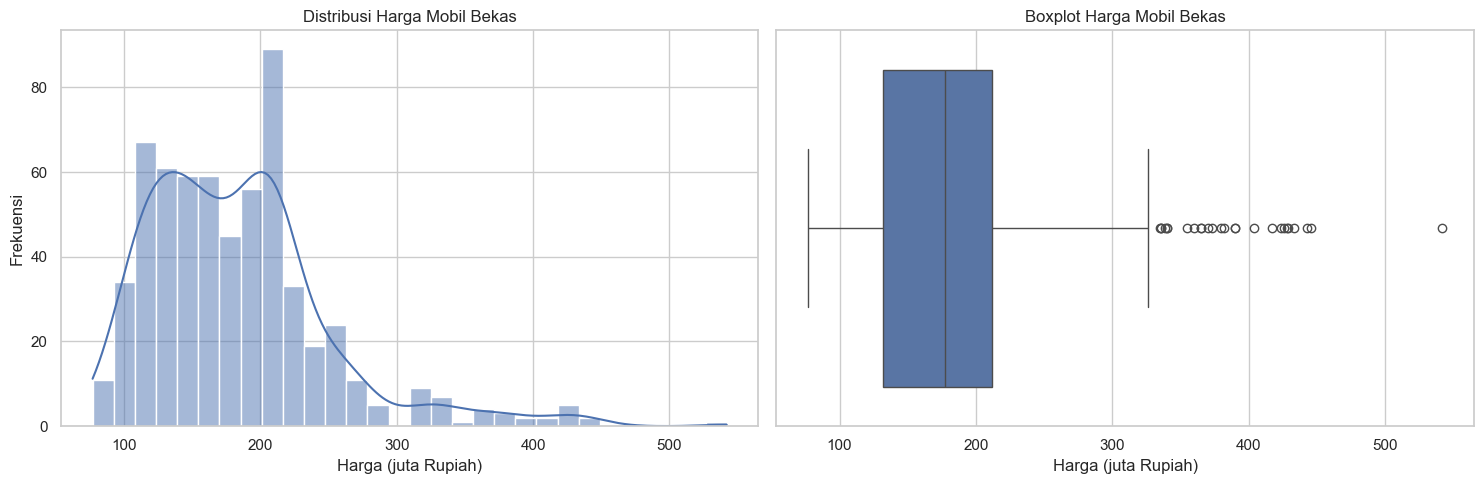

Skewness harga       : 1.452
Q1                   : Rp132,000,000
Median               : Rp177,000,000
Q3                   : Rp212,000,000
IQR                  : Rp80,000,000
Batas bawah IQR      : Rp12,000,000
Batas atas IQR       : Rp332,000,000
Jumlah flag IQR      : 26
Persentase flag IQR  : 4.27%


In [20]:
import matplotlib.pyplot as plt

price_million = price / 1_000_000

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(price_million.dropna(), bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribusi Harga Mobil Bekas")
axes[0].set_xlabel("Harga (juta Rupiah)")
axes[0].set_ylabel("Frekuensi")

sns.boxplot(x=price_million, ax=axes[1])
axes[1].set_title("Boxplot Harga Mobil Bekas")
axes[1].set_xlabel("Harga (juta Rupiah)")

plt.tight_layout()
plt.show()

price_skewness = price.skew()
q1_price = price.quantile(0.25)
q3_price = price.quantile(0.75)
iqr_price = q3_price - q1_price
lower_price = q1_price - 1.5 * iqr_price
upper_price = q3_price + 1.5 * iqr_price

price_outlier_mask = price.notna() & (
    (price < lower_price) | (price > upper_price)
)

print(f"Skewness harga       : {price_skewness:.3f}")
print(f"Q1                   : Rp{q1_price:,.0f}")
print(f"Median               : Rp{price.median():,.0f}")
print(f"Q3                   : Rp{q3_price:,.0f}")
print(f"IQR                  : Rp{iqr_price:,.0f}")
print(f"Batas bawah IQR      : Rp{lower_price:,.0f}")
print(f"Batas atas IQR       : Rp{upper_price:,.0f}")
print(f"Jumlah flag IQR      : {int(price_outlier_mask.sum())}")
print(f"Persentase flag IQR  : {price_outlier_mask.mean() * 100:.2f}%")


## 5. Distribusi Tahun Produksi

Gunakan histogram untuk melihat konsentrasi tahun produksi dan boxplot untuk memeriksa rentang serta nilai yang berpotensi ekstrem.


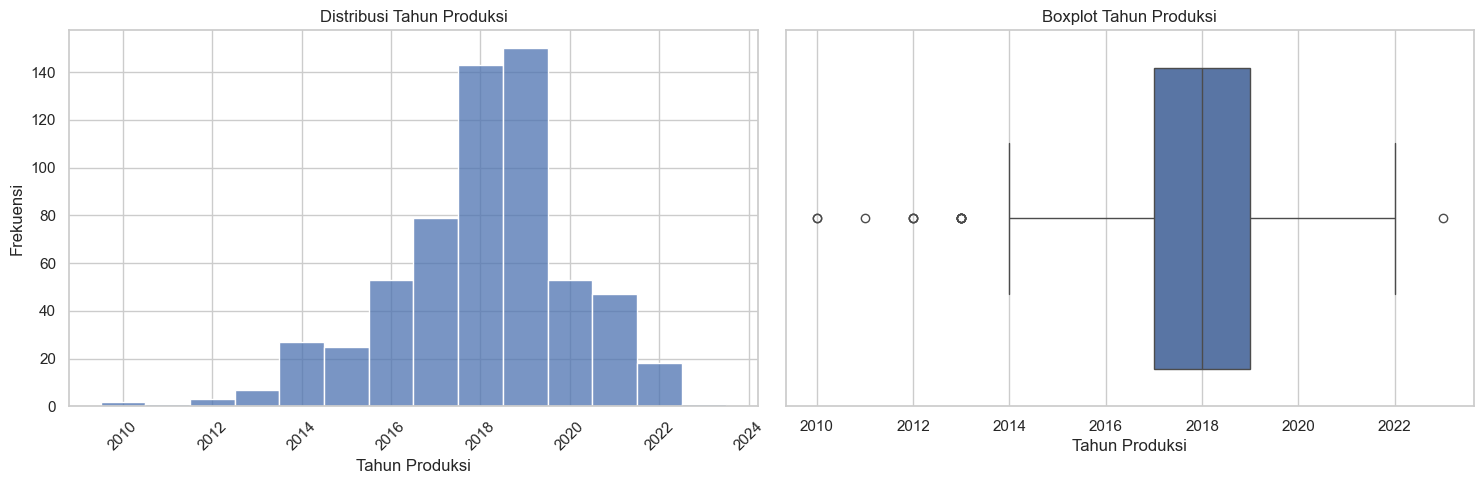

,Statistik Tahun Produksi
count,609.00
mean,"2,018.05"
std,2.03
min,"2,010.00"
25%,"2,017.00"
50%,"2,018.00"
75%,"2,019.00"
max,"2,023.00"


In [21]:
year_valid = year.dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(year_valid, bins=max(5, min(20, year_valid.nunique())), discrete=True, ax=axes[0])
axes[0].set_title("Distribusi Tahun Produksi")
axes[0].set_xlabel("Tahun Produksi")
axes[0].set_ylabel("Frekuensi")
axes[0].tick_params(axis="x", rotation=45)

sns.boxplot(x=year_valid, ax=axes[1])
axes[1].set_title("Boxplot Tahun Produksi")
axes[1].set_xlabel("Tahun Produksi")

plt.tight_layout()
plt.show()

display(
    year_valid.describe().to_frame("Statistik Tahun Produksi")
)


## 6. Distribusi Mileage

Grafik menggunakan nilai sebagaimana tersimpan pada CSV. Jangan mengubah titik menjadi pemisah ribuan atau desimal dan jangan melakukan konversi satuan sebelum format sumber dikonfirmasi.


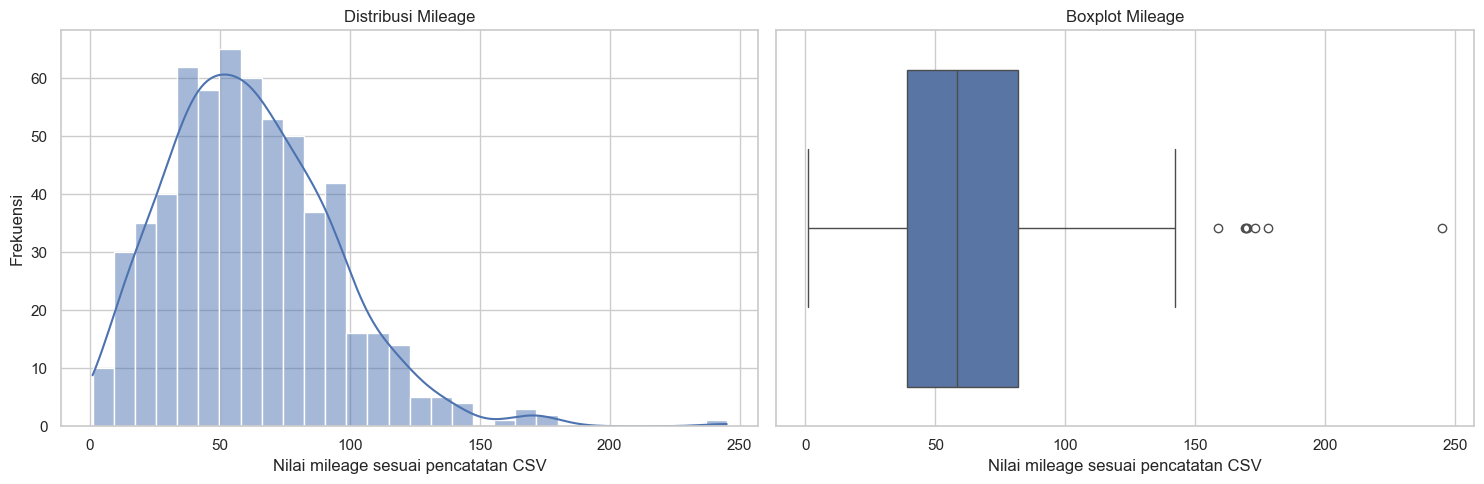

,Statistik Mileage
count,609.00
mean,61.69
std,32.15
min,1.06
25%,39.15
50%,58.37
75%,81.73
max,245.00



Contoh nilai mileage sebagaimana tersimpan:


,mileage (km)
0,10.51
1,112.89
2,118.43
3,15.95
4,30.40
5,17.31
6,12.21
7,126.89
8,33.46
9,33.36


In [22]:
mileage_valid = mileage.dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(mileage_valid, bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribusi Mileage")
axes[0].set_xlabel("Nilai mileage sesuai pencatatan CSV")
axes[0].set_ylabel("Frekuensi")

sns.boxplot(x=mileage_valid, ax=axes[1])
axes[1].set_title("Boxplot Mileage")
axes[1].set_xlabel("Nilai mileage sesuai pencatatan CSV")

plt.tight_layout()
plt.show()

display(mileage_valid.describe().to_frame("Statistik Mileage"))
print("\nContoh nilai mileage sebagaimana tersimpan:")
display(df[["mileage (km)"]].head(15))


## 7. Analisis Harga Berdasarkan Merek

Tabel menampilkan jumlah observasi, rata-rata, median, minimum, dan maksimum harga per merek. Perhatikan jumlah observasi setiap merek saat membandingkan statistiknya.


,jumlah,rata_rata,median,minimum,maksimum
brand,,,,,
BMW,1,"446,000,000.00","446,000,000.00",446000000,446000000
Hyundai,3,"327,333,333.33","319,000,000.00",246000000,417000000
Mitsubishi,63,"227,000,000.00","211,000,000.00",157000000,443000000
Mazda,19,"252,368,421.05","209,000,000.00",162000000,433000000
Wuling,24,"180,979,166.67","200,500,000.00",101500000,273000000
Toyota,171,"193,941,520.47","186,000,000.00",82000000,542000000
Honda,145,"183,386,206.90","163,000,000.00",102000000,382000000
Suzuki,62,"155,879,032.26","156,000,000.00",86000000,241000000
Nissan,33,"161,212,121.21","148,000,000.00",95000000,326000000


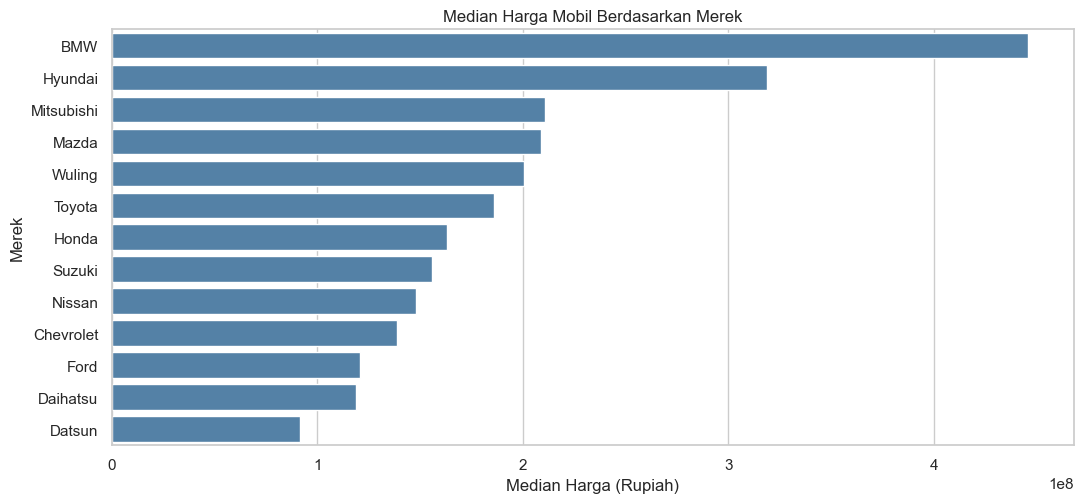

In [23]:
brand_analysis = df[["brand"]].copy()
brand_analysis["price"] = price
brand_analysis = brand_analysis.dropna(subset=["brand", "price"])

brand_summary = (
    brand_analysis.groupby("brand")["price"]
    .agg(
        jumlah="count",
        rata_rata="mean",
        median="median",
        minimum="min",
        maksimum="max"
    )
    .sort_values("median", ascending=False)
)

display(brand_summary)

brand_plot_data = brand_summary.reset_index()

plt.figure(figsize=(11, max(5, 0.4 * len(brand_plot_data))))
sns.barplot(
    data=brand_plot_data,
    y="brand",
    x="median",
    color="steelblue"
)
plt.title("Median Harga Mobil Berdasarkan Merek")
plt.xlabel("Median Harga (Rupiah)")
plt.ylabel("Merek")
plt.tight_layout()
plt.show()


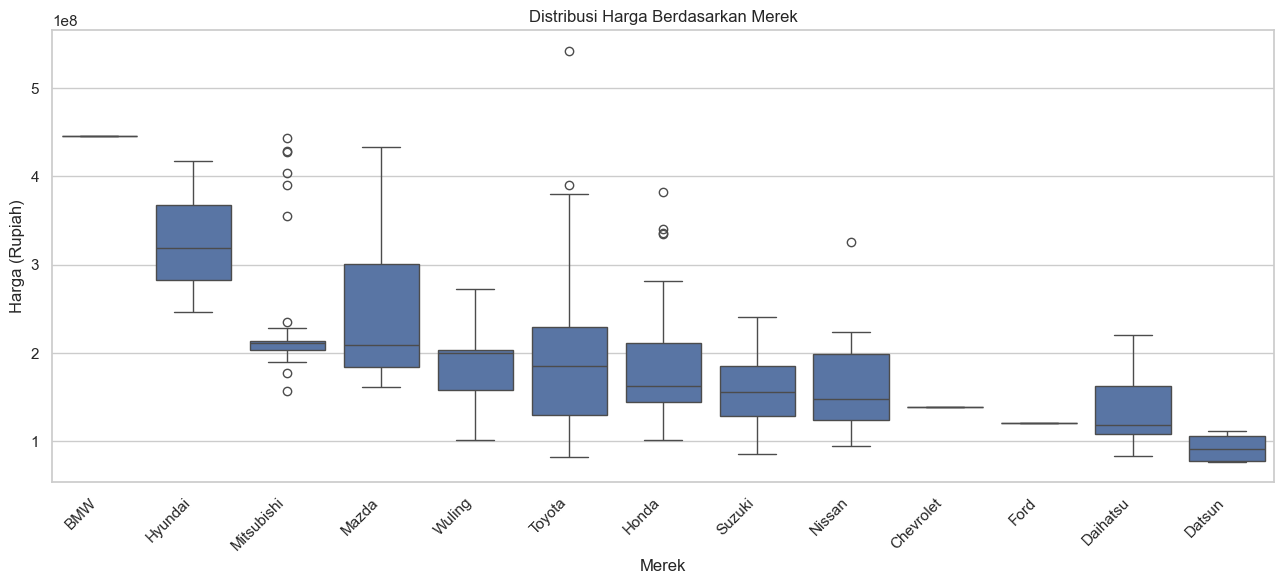

In [24]:
brand_order = brand_summary.index.tolist()

plt.figure(figsize=(13, 6))
sns.boxplot(
    data=brand_analysis,
    x="brand",
    y="price",
    order=brand_order
)
plt.title("Distribusi Harga Berdasarkan Merek")
plt.xlabel("Merek")
plt.ylabel("Harga (Rupiah)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 8. Analisis Harga Berdasarkan Transmisi

Bandingkan jumlah observasi, rata-rata, median, dan sebaran harga per kategori transmisi. Hasil ini bersifat deskriptif dan tidak membuktikan hubungan sebab-akibat.


,jumlah,rata_rata,median,minimum,maksimum
transmission,,,,,
Automatic,446,"200,524,663.68","197,000,000.00",86000000,542000000
Manual,163,"134,966,257.67","122,000,000.00",77000000,256000000


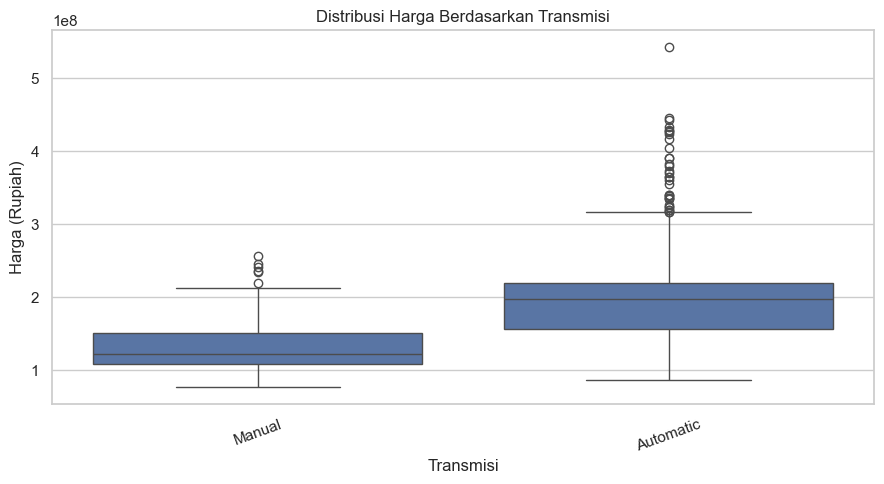

In [25]:
transmission_analysis = df[["transmission"]].copy()
transmission_analysis["price"] = price
transmission_analysis = transmission_analysis.dropna(subset=["transmission", "price"])

transmission_summary = (
    transmission_analysis.groupby("transmission")["price"]
    .agg(
        jumlah="count",
        rata_rata="mean",
        median="median",
        minimum="min",
        maksimum="max"
    )
    .sort_values("median", ascending=False)
)

display(transmission_summary)

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=transmission_analysis,
    x="transmission",
    y="price"
)
plt.title("Distribusi Harga Berdasarkan Transmisi")
plt.xlabel("Transmisi")
plt.ylabel("Harga (Rupiah)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 9. Hubungan Tahun Produksi dengan Harga

Scatterplot digunakan untuk mengamati pola hubungan tahun produksi dan harga. Korelasi dihitung menggunakan Pearson dan Spearman sebagai ukuran asosiasi, bukan bukti kausalitas.


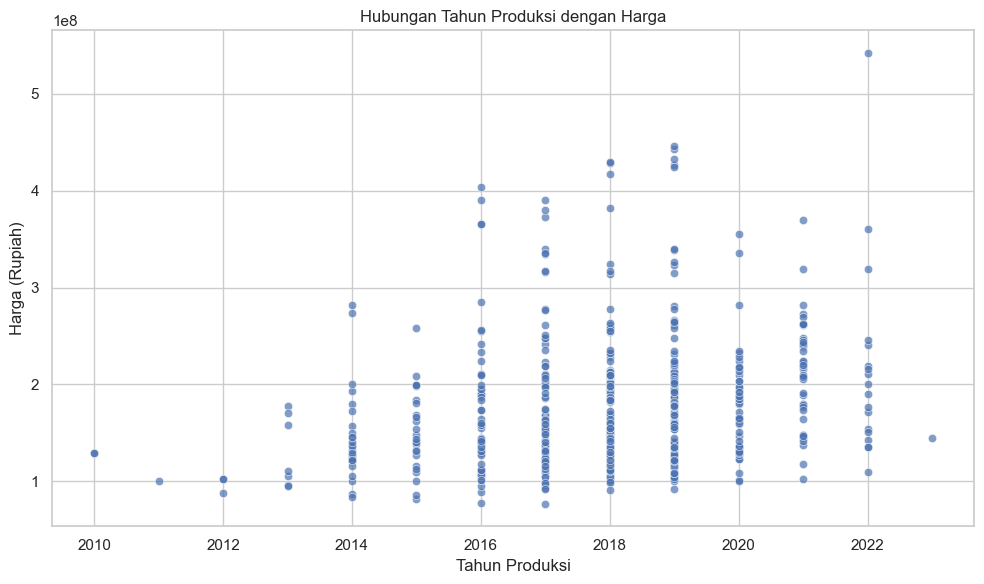

Korelasi Pearson : 0.23054022728401677
Korelasi Spearman: 0.2514172472348229


In [26]:
year_price = pd.DataFrame({
    "year": year,
    "price": price
}).dropna()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=year_price, x="year", y="price", alpha=0.7)
plt.title("Hubungan Tahun Produksi dengan Harga")
plt.xlabel("Tahun Produksi")
plt.ylabel("Harga (Rupiah)")
plt.tight_layout()
plt.show()

if len(year_price) >= 2:
    print("Korelasi Pearson :", year_price["year"].corr(year_price["price"], method="pearson"))
    print("Korelasi Spearman:", year_price["year"].corr(year_price["price"], method="spearman"))
else:
    print("Data valid tidak cukup untuk menghitung korelasi.")


## 10. Hubungan Mileage dengan Harga

Interpretasi hubungan mileage dengan harga harus mempertimbangkan bahwa format dan satuan mileage masih perlu diverifikasi.


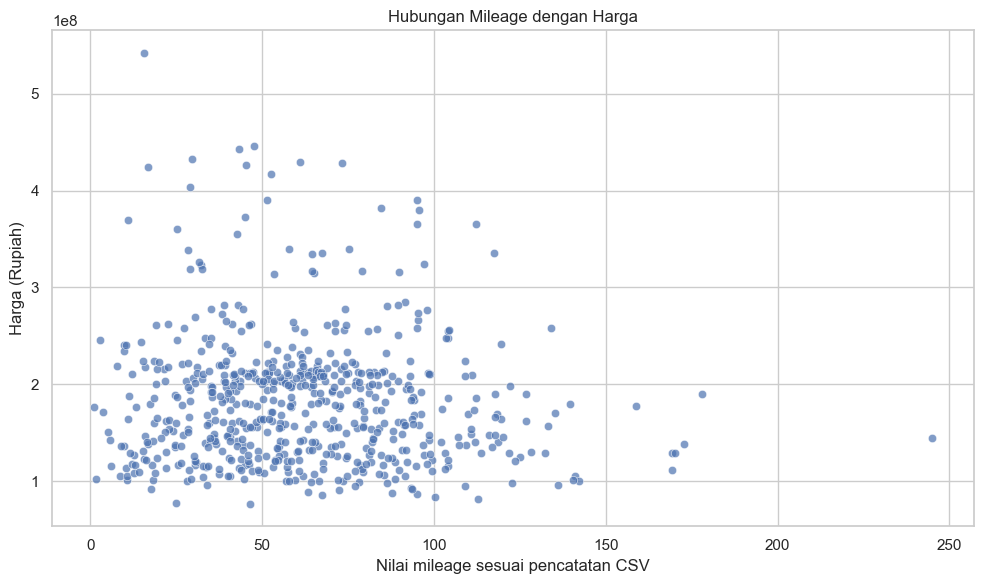

Korelasi Pearson : -0.07714645476341282
Korelasi Spearman: -0.04899329567978148


In [27]:
mileage_price = pd.DataFrame({
    "mileage": mileage,
    "price": price
}).dropna()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=mileage_price, x="mileage", y="price", alpha=0.7)
plt.title("Hubungan Mileage dengan Harga")
plt.xlabel("Nilai mileage sesuai pencatatan CSV")
plt.ylabel("Harga (Rupiah)")
plt.tight_layout()
plt.show()

if len(mileage_price) >= 2:
    print("Korelasi Pearson :", mileage_price["mileage"].corr(mileage_price["price"], method="pearson"))
    print("Korelasi Spearman:", mileage_price["mileage"].corr(mileage_price["price"], method="spearman"))
else:
    print("Data valid tidak cukup untuk menghitung korelasi.")


## 11. Analisis Fitur Biner terhadap Harga

Fitur biner yang ditemukan akan diperiksa nilai uniknya terlebih dahulu. Ringkasan membandingkan jumlah observasi dan median harga untuk nilai 0 dan 1. Kategori yang tidak memiliki nilai 0/1 akan ditandai dan tidak dipaksakan ke analisis biner.


In [28]:
binary_features = [
    "rear camera",
    "sun roof",
    "auto retract mirror",
    "electric parking brake",
    "map navigator",
    "vehicle stability control",
    "keyless push start",
    "sports mode",
    "360 camera view",
    "power sliding door",
    "auto cruise control"
]

available_binary_features = [
    column for column in binary_features if column in df.columns
]

binary_rows = []
valid_binary_features = []

for column in available_binary_features:
    values = pd.to_numeric(df[column], errors="coerce")
    observed_values = set(values.dropna().unique())

    if observed_values.issubset({0, 1}) and len(observed_values) > 0:
        valid_binary_features.append(column)
        for value in [0, 1]:
            mask = values.eq(value)
            binary_rows.append({
                "fitur": column,
                "nilai": value,
                "jumlah": int(mask.sum()),
                "median_harga": price[mask].median()
            })
    else:
        print(f"Perlu diperiksa, bukan biner 0/1: {column}; nilai unik={sorted(observed_values, key=str)}")

binary_summary = pd.DataFrame(binary_rows)
display(binary_summary)


,fitur,nilai,jumlah,median_harga
0,rear camera,0,522,"174,000,000.00"
1,rear camera,1,87,"183,000,000.00"
2,sun roof,0,591,"172,000,000.00"
3,sun roof,1,18,"227,500,000.00"
4,auto retract mirror,0,323,"140,000,000.00"
5,auto retract mirror,1,286,"208,000,000.00"
6,electric parking brake,0,590,"172,000,000.00"
7,electric parking brake,1,19,"248,000,000.00"
8,map navigator,0,603,"176,000,000.00"
9,map navigator,1,6,"190,000,000.00"


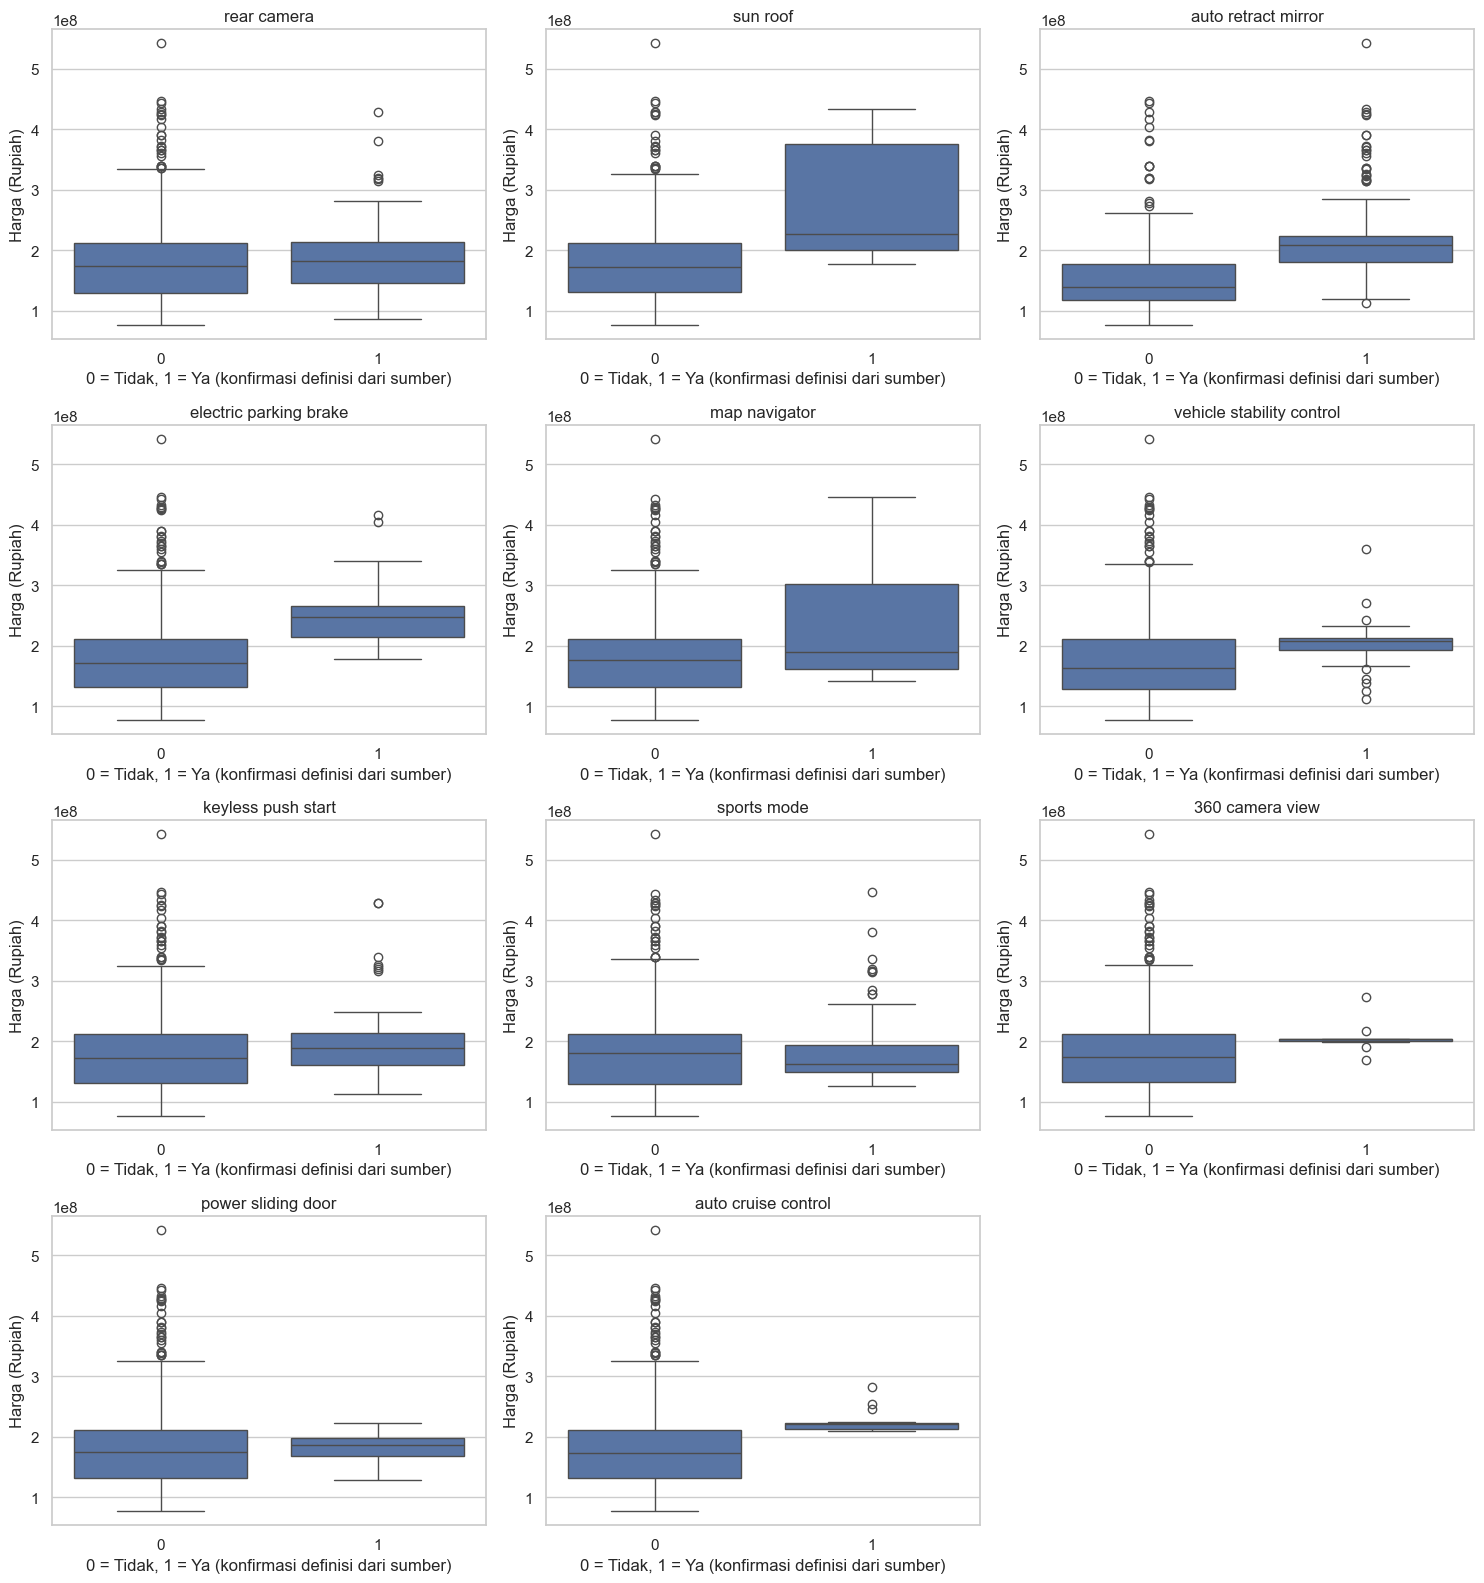

In [29]:
import numpy as np

if valid_binary_features:
    n_features = len(valid_binary_features)
    n_cols = 3
    n_rows = int(np.ceil(n_features / n_cols))

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(15, 4 * n_rows),
        squeeze=False
    )

    for index, column in enumerate(valid_binary_features):
        row, col = divmod(index, n_cols)
        plot_data = pd.DataFrame({
            "status": pd.to_numeric(df[column], errors="coerce"),
            "price": price
        }).dropna()

        sns.boxplot(data=plot_data, x="status", y="price", ax=axes[row, col])
        axes[row, col].set_title(column)
        axes[row, col].set_xlabel("0 = Tidak, 1 = Ya (konfirmasi definisi dari sumber)")
        axes[row, col].set_ylabel("Harga (Rupiah)")

    for index in range(n_features, n_rows * n_cols):
        row, col = divmod(index, n_cols)
        axes[row, col].set_visible(False)

    plt.tight_layout()
    plt.show()
else:
    print("Tidak ditemukan fitur yang terverifikasi sebagai biner 0/1.")


## 12. Analisis Korelasi

Korelasi Pearson dan Spearman dihitung pada kolom numerik. Variabel cicilan tetap ditampilkan untuk audit hubungan dengan target, tetapi harus diperlakukan sebagai kandidat data leakage dan bukan otomatis sebagai fitur prediktor.


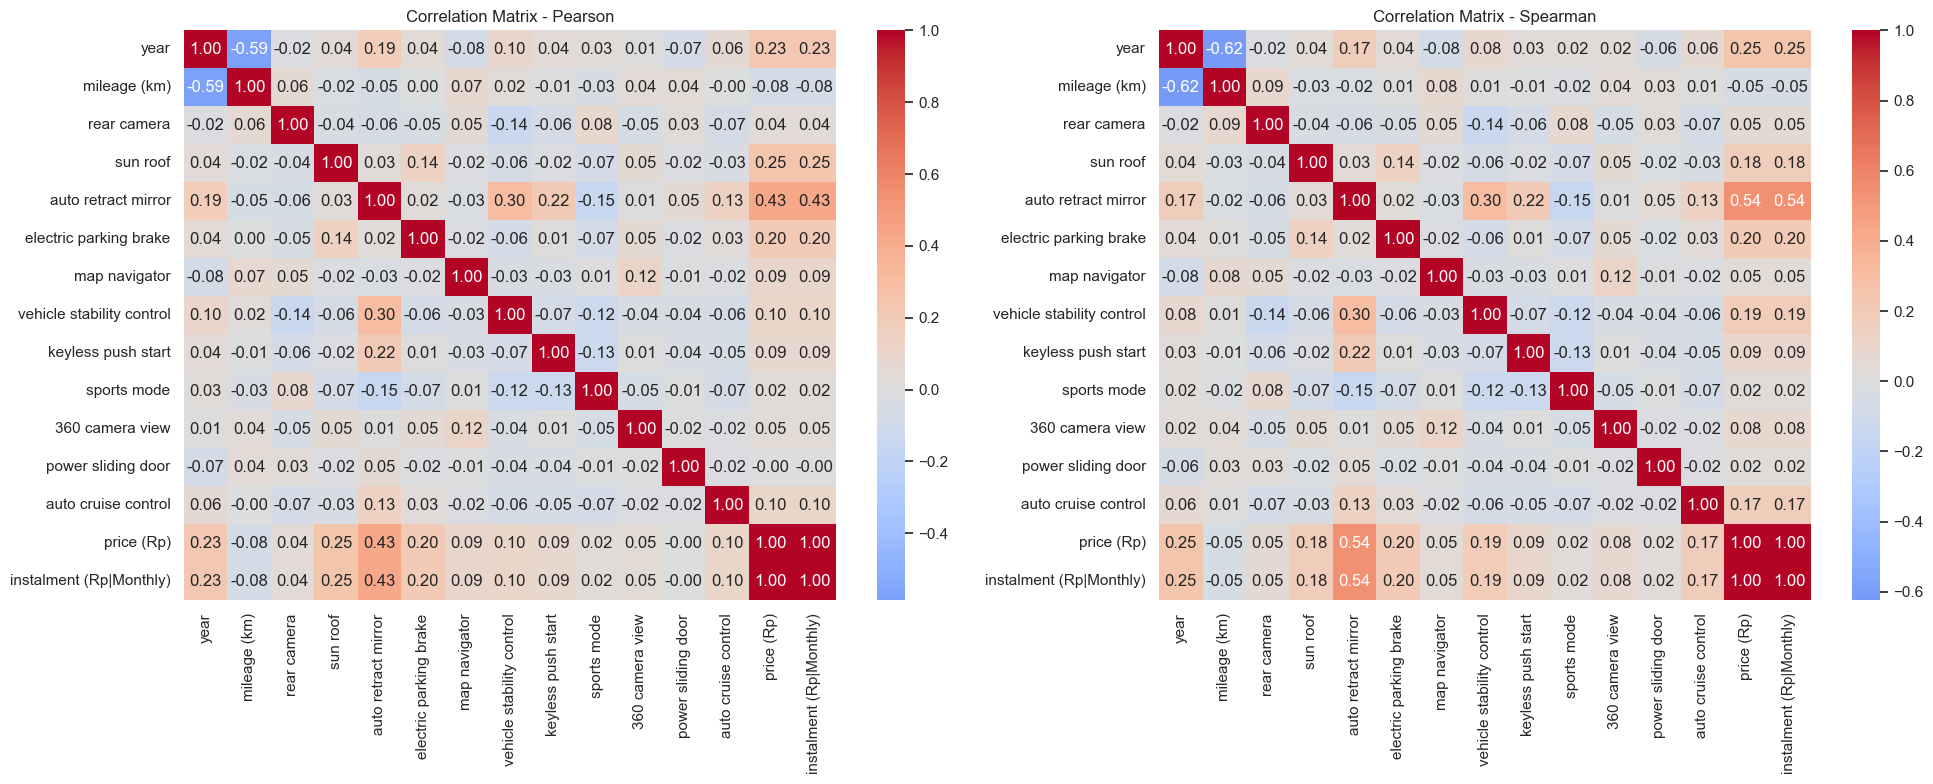

In [30]:
numeric_df = df.select_dtypes(include="number").copy()

if TARGET not in numeric_df.columns:
    numeric_df[TARGET] = price

pearson_corr = numeric_df.corr(method="pearson")
spearman_corr = numeric_df.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(
    pearson_corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    ax=axes[0]
)
axes[0].set_title("Correlation Matrix - Pearson")

sns.heatmap(
    spearman_corr,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    ax=axes[1]
)
axes[1].set_title("Correlation Matrix - Spearman")

plt.tight_layout()
plt.show()


In [31]:
if TARGET in pearson_corr.columns:
    target_corr = pd.DataFrame({
        "pearson": pearson_corr[TARGET],
        "spearman": spearman_corr[TARGET]
    }).drop(index=TARGET, errors="ignore")

    display(target_corr.sort_values("pearson", key=lambda series: series.abs(), ascending=False))

    if "instalment (Rp|Monthly)" in target_corr.index:
        print(
            "PERHATIAN: korelasi cicilan dengan harga =",
            target_corr.loc["instalment (Rp|Monthly)", "pearson"],
            ". Evaluasi sebagai potensi data leakage; jangan otomatis dipakai sebagai fitur."
        )


,pearson,spearman
instalment (Rp|Monthly),1.00,1.00
auto retract mirror,0.43,0.54
sun roof,0.25,0.18
year,0.23,0.25
electric parking brake,0.20,0.20
auto cruise control,0.10,0.17
vehicle stability control,0.10,0.19
map navigator,0.09,0.05
keyless push start,0.09,0.09
mileage (km),-0.08,-0.05


PERHATIAN: korelasi cicilan dengan harga = 0.9999979190615439 . Evaluasi sebagai potensi data leakage; jangan otomatis dipakai sebagai fitur.


## 13. Ringkasan Insight EDA

Berdasarkan hasil analisis yang telah tersedia, berikut tiga insight awal yang dapat dipertanggungjawabkan. Insight ini menggunakan hasil histogram, boxplot, statistik deskriptif, perhitungan IQR, dan pemeriksaan korelasi yang telah dilakukan sebelumnya.

### Insight 1. Distribusi harga mobil bekas cenderung menceng ke kanan (*positively skewed*)

**Temuan:** Distribusi harga mobil bekas tidak simetris dan menunjukkan kemencengan ke kanan.

**Bukti:** Nilai skewness harga sekitar **1,452**. Median harga sekitar **Rp177.000.000**, dengan kuartil pertama (Q1) sekitar **Rp132.000.000** dan kuartil ketiga (Q3) sekitar **Rp212.000.000**. Histogram menunjukkan sebagian besar observasi terkonsentrasi pada kisaran kurang lebih **Rp100 juta hingga Rp230 juta**, sedangkan terdapat sejumlah kecil mobil dengan harga jauh lebih tinggi, hingga sekitar **Rp542 juta**.

**Interpretasi:** Sebagian besar mobil dalam dataset berada pada kelompok harga menengah, sementara sebagian kecil kendaraan memiliki harga relatif tinggi. Ekor distribusi yang memanjang ke kanan menyebabkan distribusi harga tidak simetris.

**Implikasi terhadap Data Quality Audit/Data Cleaning:** Perlu dilakukan pemeriksaan lebih lanjut terhadap harga yang sangat tinggi untuk memastikan bahwa nilai tersebut merupakan harga kendaraan yang valid, bukan kesalahan pencatatan. Kemencengan distribusi juga perlu dipertimbangkan ketika mengevaluasi kebutuhan transformasi target.

**Implikasi terhadap Feature Selection/Modeling:** Evaluasi performa model perlu memperhatikan kemungkinan pengaruh observasi berharga tinggi terhadap kesalahan prediksi. Transformasi logaritmik terhadap target dapat diuji sebagai eksperimen, tetapi tidak boleh diterapkan tanpa membandingkan performa model sebelum dan sesudah transformasi.

### Insight 2. Terdapat observasi harga yang terindikasi sebagai outlier berdasarkan metode IQR

**Temuan:** Sebagian observasi memiliki harga yang berada di luar batas atas IQR.

**Bukti:** Dengan Q1 sekitar **Rp132.000.000** dan Q3 sekitar **Rp212.000.000**, diperoleh IQR sekitar **Rp80.000.000**. Batas atas IQR adalah sekitar **Rp332.000.000**. Pemeriksaan awal menandai **26 observasi** sebagai outlier harga dari total **609 observasi**, atau sekitar **4,27%**.

**Interpretasi:** Sebagian kecil kendaraan memiliki harga yang jauh lebih tinggi dibandingkan rentang tengah distribusi harga. Status outlier berdasarkan IQR hanya menunjukkan posisi nilai yang ekstrem secara statistik, bukan membuktikan bahwa data tersebut salah.

**Implikasi terhadap Data Quality Audit/Data Cleaning:** Seluruh observasi yang terindikasi perlu diperiksa berdasarkan informasi kendaraan, seperti merek, model, tahun produksi, dan fitur kendaraan. Observasi yang valid harus dipertahankan. Penghapusan atau pembatasan nilai hanya dapat dilakukan jika ditemukan alasan yang kuat dan terdokumentasi.

**Implikasi terhadap Feature Selection/Modeling:** Model berbasis pohon dan model regresi linear dapat merespons observasi ekstrem secara berbeda. Karena itu, evaluasi model sebaiknya membandingkan metrik dan residual, serta menguji strategi penanganan outlier hanya jika didukung hasil audit.

### Insight 3. Variabel cicilan memiliki hubungan yang hampir sempurna dengan harga dan berpotensi menyebabkan data leakage

**Temuan:** Variabel `instalment (Rp|Monthly)` memiliki korelasi yang hampir sempurna dengan variabel target `price (Rp)`.

**Bukti:** Pemeriksaan korelasi sebelumnya menunjukkan nilai korelasi sekitar **0,999998** antara cicilan bulanan dan harga mobil.

**Interpretasi:** Hubungan yang hampir sempurna tersebut mengindikasikan bahwa nilai cicilan mungkin dihitung atau dibentuk secara langsung dari harga kendaraan. Jika variabel cicilan digunakan untuk memprediksi harga, model berisiko memperoleh informasi yang secara praktis sudah merepresentasikan target.

**Implikasi terhadap Data Quality Audit/Data Cleaning:** Asal-usul, rumus pembentukan, dan waktu ketersediaan variabel cicilan perlu diperiksa. Korelasi tinggi merupakan indikasi yang perlu ditelusuri, tetapi belum menjadi bukti tunggal bahwa data leakage pasti terjadi.

**Implikasi terhadap Feature Selection/Modeling:** Untuk pemodelan prediksi harga berdasarkan karakteristik kendaraan, `instalment (Rp|Monthly)` sebaiknya **tidak digunakan sebagai fitur prediktor pada eksperimen awal**. Variabel ini dapat dikeluarkan dari kandidat fitur agar evaluasi model tidak menghasilkan performa yang tampak sangat tinggi akibat kebocoran informasi target.

---

### Catatan batasan interpretasi

Tiga insight di atas merupakan insight awal berdasarkan hasil yang sudah tersedia. Insight tambahan mengenai mileage, perbedaan harga antarmerek, transmisi, serta hubungan tahun produksi dengan harga harus ditulis setelah output analisis terkait dijalankan dan diperiksa. Jangan mengisi temuan tersebut dengan asumsi.

### Ringkasan implikasi

| No. | Insight | Tindak lanjut |
|---|---|---|
| 1 | Distribusi harga menceng ke kanan | Evaluasi transformasi target dan residual model |
| 2 | 26 observasi harga terindikasi outlier IQR | Periksa validitas setiap observasi sebelum menentukan penanganan |
| 3 | Korelasi cicilan dan harga sekitar 0,999998 | Keluarkan cicilan dari fitur prediktor awal dan telusuri potensi data leakage |



---
# Bagian 3 — Data Quality Audit
*(digabung dari `03_data_quality_audit.ipynb`)*

# 03 - Data Quality Audit
## Prediksi Harga Mobil Bekas di Indonesia

Notebook ini mengidentifikasi masalah kualitas data dan mendokumentasikan temuan untuk menjadi dasar keputusan Data Cleaning.

**Penting:** notebook ini hanya melakukan audit. Jangan menghapus baris, mengimputasi nilai, mengubah satuan, atau memperbaiki data pada tahap ini.


## 1. Import Libraries


In [32]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")


## 2. Load Dataset

Baca dataset asli secara normal dan sebagai teks. Pembacaan teks membantu memeriksa representasi nilai pada CSV, khususnya format mileage.


In [33]:
candidate_paths = []

for folder in [Path.cwd(), *Path.cwd().parents]:
    candidate_paths.append(folder / "data" / "used_car.csv")
    candidate_paths.append(folder / "used_car.csv")

DATA_PATH = next((path.resolve() for path in candidate_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "File used_car.csv tidak ditemukan. Letakkan file pada folder "
        "'data' di direktori utama proyek, lalu periksa Path.cwd()."
    )

df = pd.read_csv(DATA_PATH)
df_raw = pd.read_csv(DATA_PATH, dtype="string")

print("Lokasi dataset :", DATA_PATH)
print("Dimensi dataset:", df.shape)
print("Dimensi raw text:", df_raw.shape)

if df.shape != df_raw.shape:
    raise ValueError("Dimensi pembacaan normal dan raw text tidak sama. Periksa parsing CSV.")

display(df.head())


Lokasi dataset : C:\Users\Carbon\OneDrive\Documents\KULIAH UPN\SEMESTER 5\Prak DataScience\project\32_IF-C_bersifatopsional\Data\used_car.csv
Dimensi dataset: (609, 20)
Dimensi raw text: (609, 20)


,car name,brand,year,mileage (km),location,transmission,plate type,rear camera,sun roof,auto retract mirror,electric parking brake,map navigator,vehicle stability control,keyless push start,sports mode,360 camera view,power sliding door,auto cruise control,price (Rp),instalment (Rp|Monthly)
0,AYLA X 1.2,Daihatsu,2018,10.508,Jakarta Utara,Manual,even plate,0,0,0,0,0,0,0,0,0,0,0,101000000,2060000
1,AGYA TRD SPORTIVO 1.0,Toyota,2015,112.888,Bogor,Manual,even plate,0,0,0,0,0,0,0,0,0,0,0,82000000,1670000
2,X-TRAIL 2.5,Nissan,2015,118.429,Surabaya,Automatic,odd plate,0,0,0,0,0,0,1,0,1,0,0,169000000,3440000
3,YARIS S TRD 1.5,Toyota,2020,15.945,Tangerang Selatan,Automatic,odd plate,0,0,0,0,0,0,0,0,0,0,0,218000000,4440000
4,AGYA G 1.2,Toyota,2019,30.404,Jakarta Barat,Manual,odd plate,0,0,0,0,0,0,0,0,0,0,0,117000000,2380000


## 3. Pemeriksaan Struktur dan Tipe Data


In [34]:
structure_audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "n_unique": df.nunique(dropna=True)
})

display(structure_audit)


,dtype,non_null,missing,missing_pct,n_unique
car name,object,609,0,0.000,172
brand,object,609,0,0.000,13
year,int64,609,0,0.000,14
mileage (km),float64,609,0,0.000,609
location,object,609,0,0.000,13
transmission,object,609,0,0.000,2
plate type,object,609,0,0.000,2
rear camera,int64,609,0,0.000,2
sun roof,int64,609,0,0.000,2
auto retract mirror,int64,609,0,0.000,2


## 4. Audit Missing Values


In [35]:
missing_audit = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

display(missing_audit)

print("Total missing value:", int(df.isna().sum().sum()))


,missing_count,missing_percentage
car name,0,0.000
brand,0,0.000
year,0,0.000
mileage (km),0,0.000
location,0,0.000
transmission,0,0.000
plate type,0,0.000
rear camera,0,0.000
sun roof,0,0.000
auto retract mirror,0,0.000


Total missing value: 0


## 5. Audit Duplikasi

Pemeriksaan ini menghitung duplikasi baris secara persis. Duplikasi persis perlu ditinjau, tetapi belum otomatis dihapus.


In [36]:
duplicate_mask = df.duplicated(keep=False)
duplicate_rows = df.loc[duplicate_mask].copy()

print("Jumlah baris duplikat (semua kemunculan):", int(duplicate_mask.sum()))
print("Jumlah baris duplikat setelah kemunculan pertama:", int(df.duplicated().sum()))

if not duplicate_rows.empty:
    display(duplicate_rows.head(20))
else:
    print("Tidak ditemukan baris duplikat secara persis.")


Jumlah baris duplikat (semua kemunculan): 0
Jumlah baris duplikat setelah kemunculan pertama: 0
Tidak ditemukan baris duplikat secara persis.


## 6. Audit Tipe Data dan Kegagalan Konversi Numerik

Bandingkan kolom numerik yang diharapkan dengan hasil konversi. Nilai yang tidak dapat dikonversi perlu diperiksa, bukan langsung diperbaiki.


In [37]:
expected_numeric_columns = [
    "year",
    "mileage (km)",
    "price (Rp)",
    "instalment (Rp|Monthly)"
]

numeric_conversion_rows = []

for column in expected_numeric_columns:
    if column not in df_raw.columns:
        numeric_conversion_rows.append({
            "kolom": column,
            "status": "Kolom tidak ditemukan",
            "jumlah_gagal_konversi": np.nan,
            "contoh_nilai_gagal": None
        })
        continue

    raw_values = df_raw[column]
    converted = pd.to_numeric(raw_values, errors="coerce")

    failed_mask = raw_values.notna() & converted.isna()
    examples = raw_values.loc[failed_mask].drop_duplicates().head(10).tolist()

    numeric_conversion_rows.append({
        "kolom": column,
        "status": str(df[column].dtype) if column in df.columns else "Tidak tersedia",
        "jumlah_gagal_konversi": int(failed_mask.sum()),
        "contoh_nilai_gagal": examples
    })

numeric_conversion_audit = pd.DataFrame(numeric_conversion_rows)
display(numeric_conversion_audit)


,kolom,status,jumlah_gagal_konversi,contoh_nilai_gagal
0,year,int64,0,[]
1,mileage (km),float64,0,[]
2,price (Rp),int64,0,[]
3,instalment (Rp|Monthly),int64,0,[]


## 7. Pemeriksaan Format Mileage

Tampilkan nilai mileage dalam bentuk teks mentah dan bentuk hasil pembacaan Pandas. Tujuannya melihat apakah ada pemisah, simbol, atau format yang memerlukan verifikasi dari dokumentasi sumber.

**Jangan** mengasumsikan tanda titik sebagai pemisah ribuan atau desimal sebelum ada bukti dari sumber dataset.


In [38]:
if "mileage (km)" in df.columns:
    mileage_format_check = pd.DataFrame({
        "raw_csv_value": df_raw["mileage (km)"].head(30),
        "pandas_value": df["mileage (km)"].head(30),
        "pandas_dtype": str(df["mileage (km)"].dtype)
    })
    display(mileage_format_check)

    print("Contoh nilai mileage unik dari CSV:")
    display(df_raw["mileage (km)"].dropna().drop_duplicates().head(30))
else:
    print("Kolom mileage (km) tidak ditemukan.")


,raw_csv_value,pandas_value,pandas_dtype
0,10.508,10.508,float64
1,112.888,112.888,float64
2,118.429,118.429,float64
3,15.945,15.945,float64
4,30.404,30.404,float64
5,17.306,17.306,float64
6,12.211,12.211,float64
7,126.885,126.885,float64
8,33.464,33.464,float64
9,33.364,33.364,float64


Contoh nilai mileage unik dari CSV:


0      10.508
1     112.888
2     118.429
3      15.945
4      30.404
5      17.306
6      12.211
7     126.885
8      33.464
9      33.364
10     44.969
11     43.292
12     57.385
13     53.151
14     46.182
15     58.152
16    118.704
17     78.385
18     45.376
19     37.343
20     61.937
21     47.085
22        178
23     10.301
24     75.302
25     18.298
26     50.387
27     64.235
28     44.473
29     24.577
Name: mileage (km), dtype: string

## 8. Audit Nilai Kategorikal dan Whitespace

Periksa spasi di awal/akhir nilai kategori, string kosong, dan kategori yang menandakan informasi tidak diketahui. Pemeriksaan ini tidak mengubah nilai.


In [39]:
categorical_columns = df.select_dtypes(include=["object", "string"]).columns.tolist()

categorical_audit_rows = []

unknown_tokens = {
    "unknown", "unk", "n/a", "na", "not available", "none", "null", "-"
}

for column in categorical_columns:
    values = df_raw[column].dropna().astype("string")
    stripped = values.str.strip()

    whitespace_count = int((values != stripped).sum())
    empty_after_strip = int(stripped.eq("").sum())
    unknown_count = int(stripped.str.lower().isin(unknown_tokens).sum())

    categorical_audit_rows.append({
        "kolom": column,
        "jumlah_kategori_unik": int(stripped.nunique()),
        "nilai_dengan_whitespace": whitespace_count,
        "string_kosong_setelah_strip": empty_after_strip,
        "unknown_or_placeholder": unknown_count
    })

categorical_audit = pd.DataFrame(categorical_audit_rows)
display(categorical_audit)


,kolom,jumlah_kategori_unik,nilai_dengan_whitespace,string_kosong_setelah_strip,unknown_or_placeholder
0,car name,172,0,0,0
1,brand,13,0,0,0
2,location,13,0,0,52
3,transmission,2,0,0,0
4,plate type,2,0,0,0


In [40]:
for column in categorical_columns:
    print(f"\n{column} — kategori dan frekuensi:")
    display(df[column].value_counts(dropna=False).head(30))



car name — kategori dan frekuensi:


car name
BRIO SATYA E 1.2              48
XPANDER ULTIMATE 1.5          38
CALYA G 1.2                   21
AYLA R 1.2                    19
RUSH S TRD SPORTIVO 1.5       18
BRIO RS 1.2                   17
AGYA G TRD 1.2                16
HR-V E 1.5                    15
AVANZA G 1.3                  14
MOBILIO E 1.5                 12
AYLA X 1.0                     9
YARIS S TRD 1.5                9
KIJANG INNOVA REBORN G 2.0     9
IGNIS GX 1.2                   8
XPANDER SPORT 1.5              7
KIJANG INNOVA G 2.0            7
TERIOS R 1.5                   6
CITY RS HATCHBACK 1.5          6
LIVINA VL 1.5                  6
ALMAZ LT LUX 1.5               6
BALENO HATCHBACK 1.4           6
XPANDER EXCEED 1.5             6
BR-V E 1.5                     6
SX4 S-CROSS 1.5                6
AGYA G 1.0                     5
AYLA R DLX 1.2                 5
MOBILIO RS 1.5                 5
HR-V SE 1.5                    5
HR-V E PLUS 1.5                5
IGNIS GL 1.2                   5
N


brand — kategori dan frekuensi:


brand
Toyota        171
Honda         145
Daihatsu       82
Mitsubishi     63
Suzuki         62
Nissan         33
Wuling         24
Mazda          19
Datsun          4
Hyundai         3
Chevrolet       1
Ford            1
BMW             1
Name: count, dtype: int64


location — kategori dan frekuensi:


location
Bogor                104
Tangerang Selatan     98
Bekasi                68
Jakarta Utara         54
Unknown               52
Jakarta Timur         50
Jakarta Barat         45
Bandung               45
Depok                 33
Jakarta Selatan       24
Jakarta Pusat         19
Surabaya               9
Malang                 8
Name: count, dtype: int64


transmission — kategori dan frekuensi:


transmission
Automatic    446
Manual       163
Name: count, dtype: int64


plate type — kategori dan frekuensi:


plate type
even plate    321
odd plate     288
Name: count, dtype: int64

## 9. Validasi Fitur Biner

Fitur berikut diharapkan menggunakan nilai 0 dan 1. Audit ini menghitung nilai selain 0/1 dan nilai yang gagal dikonversi.


In [41]:
binary_features = [
    "rear camera",
    "sun roof",
    "auto retract mirror",
    "electric parking brake",
    "map navigator",
    "vehicle stability control",
    "keyless push start",
    "sports mode",
    "360 camera view",
    "power sliding door",
    "auto cruise control"
]

binary_audit_rows = []

for column in binary_features:
    if column not in df_raw.columns:
        binary_audit_rows.append({
            "kolom": column,
            "jumlah_0": np.nan,
            "jumlah_1": np.nan,
            "jumlah_missing": np.nan,
            "jumlah_nilai_tidak_valid": np.nan,
            "nilai_tidak_valid": "Kolom tidak ditemukan"
        })
        continue

    raw_values = df_raw[column]
    numeric_values = pd.to_numeric(raw_values, errors="coerce")

    invalid_parse = raw_values.notna() & numeric_values.isna()
    invalid_binary = numeric_values.notna() & ~numeric_values.isin([0, 1])
    invalid_mask = invalid_parse | invalid_binary

    invalid_values = raw_values.loc[invalid_mask].drop_duplicates().head(10).tolist()

    binary_audit_rows.append({
        "kolom": column,
        "jumlah_0": int(numeric_values.eq(0).sum()),
        "jumlah_1": int(numeric_values.eq(1).sum()),
        "jumlah_missing": int(raw_values.isna().sum()),
        "jumlah_nilai_tidak_valid": int(invalid_mask.sum()),
        "nilai_tidak_valid": invalid_values
    })

binary_audit = pd.DataFrame(binary_audit_rows)
display(binary_audit)


,kolom,jumlah_0,jumlah_1,jumlah_missing,jumlah_nilai_tidak_valid,nilai_tidak_valid
0,rear camera,522,87,0,0,[]
1,sun roof,591,18,0,0,[]
2,auto retract mirror,323,286,0,0,[]
3,electric parking brake,590,19,0,0,[]
4,map navigator,603,6,0,0,[]
5,vehicle stability control,546,63,0,0,[]
6,keyless push start,555,54,0,0,[]
7,sports mode,524,85,0,0,[]
8,360 camera view,599,10,0,0,[]
9,power sliding door,600,9,0,0,[]


## 10. Validasi Rentang Nilai

Periksa nilai yang secara logis tidak valid, seperti harga nol/negatif, mileage negatif, tahun nol/negatif, atau tahun produksi di masa depan. Tahun masa depan dihitung berdasarkan tahun kalender saat notebook dijalankan.


In [42]:
CURRENT_YEAR = pd.Timestamp.today().year

range_audit_rows = []

def add_range_audit(column, series, condition_name, mask):
    valid_mask = series.notna()
    count = int((mask & valid_mask).sum())
    denominator = int(valid_mask.sum())
    percentage = (count / denominator * 100) if denominator else np.nan

    range_audit_rows.append({
        "kolom": column,
        "jenis_pemeriksaan": condition_name,
        "jumlah_bermasalah": count,
        "persentase_dari_nilai_valid": percentage
    })

for column in expected_numeric_columns:
    if column not in df.columns:
        continue

    values = pd.to_numeric(df[column], errors="coerce")

    if column in ["price (Rp)", "instalment (Rp|Monthly)"]:
        add_range_audit(column, values, "Nilai nol atau negatif", values <= 0)

    elif column == "mileage (km)":
        add_range_audit(column, values, "Mileage negatif", values < 0)

    elif column == "year":
        add_range_audit(column, values, "Tahun nol atau negatif", values <= 0)
        add_range_audit(column, values, "Tahun lebih besar dari tahun saat ini", values > CURRENT_YEAR)

range_audit = pd.DataFrame(range_audit_rows)
display(range_audit)
print("Tahun kalender saat audit:", CURRENT_YEAR)


,kolom,jenis_pemeriksaan,jumlah_bermasalah,persentase_dari_nilai_valid
0,year,Tahun nol atau negatif,0,0.000
1,year,Tahun lebih besar dari tahun saat ini,0,0.000
2,mileage (km),Mileage negatif,0,0.000
3,price (Rp),Nilai nol atau negatif,0,0.000
4,instalment (Rp|Monthly),Nilai nol atau negatif,0,0.000


Tahun kalender saat audit: 2026


## 11. Outlier Detection dengan IQR

IQR digunakan untuk menandai nilai yang berada di luar batas statistik. Flag outlier bukan bukti bahwa data salah dan bukan instruksi untuk menghapus observasi.

Audit dilakukan pada variabel numerik kontinu yang relevan. Interpretasikan tahun produksi secara hati-hati karena sifatnya diskrit dan rentangnya dipengaruhi cakupan dataset.


In [43]:
iqr_columns = [
    "price (Rp)",
    "mileage (km)",
    "year",
    "instalment (Rp|Monthly)"
]

iqr_audit_rows = []
iqr_flagged_indices = {}

for column in iqr_columns:
    if column not in df.columns:
        continue

    values = pd.to_numeric(df[column], errors="coerce").dropna()

    if values.empty:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    full_values = pd.to_numeric(df[column], errors="coerce")
    mask = full_values.notna() & ((full_values < lower) | (full_values > upper))
    iqr_flagged_indices[column] = df.index[mask].tolist()

    count = int(mask.sum())
    valid_count = int(full_values.notna().sum())

    iqr_audit_rows.append({
        "kolom": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "batas_bawah": lower,
        "batas_atas": upper,
        "jumlah_flag_outlier": count,
        "persentase": (count / valid_count * 100) if valid_count else np.nan
    })

iqr_audit = pd.DataFrame(iqr_audit_rows)
display(iqr_audit)


,kolom,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_flag_outlier,persentase
0,price (Rp),"132,000,000.000","212,000,000.000","80,000,000.000","12,000,000.000","332,000,000.000",26,4.269
1,mileage (km),39.145,81.726,42.581,-24.726,145.597,7,1.149
2,year,"2,017.000","2,019.000",2.000,"2,014.000","2,022.000",14,2.299
3,instalment (Rp|Monthly),"2,690,000.000","4,320,000.000","1,630,000.000","245,000.000","6,765,000.000",26,4.269


In [44]:
# Tinjau contoh observasi yang ter-flag sebagai outlier harga.
if "price (Rp)" in iqr_flagged_indices:
    flagged_price_rows = df.loc[
        iqr_flagged_indices["price (Rp)"]
    ].sort_values("price (Rp)", ascending=False)

    print("Contoh observasi dengan harga ter-flag IQR:")
    display(flagged_price_rows.head(20))


Contoh observasi dengan harga ter-flag IQR:


,car name,brand,year,mileage (km),location,transmission,plate type,rear camera,sun roof,auto retract mirror,electric parking brake,map navigator,vehicle stability control,keyless push start,sports mode,360 camera view,power sliding door,auto cruise control,price (Rp),instalment (Rp|Monthly)
318,FORTUNER VRZ GR SPORT 2.8,Toyota,2022,15.713,Jakarta Timur,Automatic,odd plate,0,0,1,0,0,0,0,0,0,0,0,542000000,11040000
575,3 20I (CKD) 2.0,BMW,2019,47.554,Jakarta Selatan,Automatic,even plate,0,0,0,0,1,0,0,1,0,0,0,446000000,9090000
406,PAJERO SPORT DAKAR ULTIMATE 4X2 2.4,Mitsubishi,2019,43.295,Unknown,Automatic,odd plate,0,0,0,0,0,0,0,0,0,0,0,443000000,9030000
563,CX-5 ELITE 2.5,Mazda,2019,29.440,Bandung,Automatic,even plate,0,1,1,0,0,0,0,0,0,0,0,433000000,8820000
357,PAJERO SPORT DAKAR 4X2 2.4,Mitsubishi,2018,60.880,Jakarta Utara,Automatic,even plate,0,0,1,0,0,0,1,0,0,0,0,429000000,8740000
232,PAJERO SPORT DAKAR ULTIMATE 4X2 2.4,Mitsubishi,2018,73.296,Jakarta Timur,Automatic,even plate,1,0,0,0,0,0,1,0,0,0,0,428000000,8720000
70,CX-5 ELITE 2.5,Mazda,2019,45.271,Tangerang Selatan,Automatic,even plate,0,0,1,0,0,0,0,0,0,0,0,426000000,8680000
261,CX-5 GT 2.5,Mazda,2019,16.763,Jakarta Barat,Automatic,odd plate,0,0,1,0,0,0,0,0,0,0,0,424000000,8640000
255,SANTA FE CRDI 2.2,Hyundai,2018,52.497,Bekasi,Automatic,odd plate,0,1,0,1,0,0,0,0,0,0,0,417000000,8500000
559,PAJERO SPORT DAKAR 4X2 2.4,Mitsubishi,2016,28.906,Tangerang Selatan,Automatic,even plate,0,1,0,1,0,0,0,0,0,0,0,404000000,8230000


## 12. Audit Potensi Data Leakage: Cicilan dan Harga

Korelasi tinggi antara cicilan dan harga dapat menjadi indikasi bahwa cicilan dihitung berdasarkan harga. Namun, korelasi saja tidak membuktikan secara pasti bagaimana variabel tersebut dibuat.

Periksa korelasi dan hubungan rasio cicilan terhadap harga. Jangan masukkan cicilan sebagai fitur model sebelum asal-usul dan waktu ketersediaan variabel dipastikan.


In [45]:
if {"price (Rp)", "instalment (Rp|Monthly)"}.issubset(df.columns):
    leakage_check = df[["price (Rp)", "instalment (Rp|Monthly)"]].apply(
        pd.to_numeric, errors="coerce"
    ).dropna()

    if len(leakage_check) >= 2:
        pearson_value = leakage_check["price (Rp)"].corr(
            leakage_check["instalment (Rp|Monthly)"], method="pearson"
        )
        spearman_value = leakage_check["price (Rp)"].corr(
            leakage_check["instalment (Rp|Monthly)"], method="spearman"
        )

        print("Jumlah pasangan data valid:", len(leakage_check))
        print("Korelasi Pearson :", pearson_value)
        print("Korelasi Spearman:", spearman_value)

        positive_price = leakage_check["price (Rp)"] > 0
        ratio = (
            leakage_check.loc[positive_price, "instalment (Rp|Monthly)"]
            / leakage_check.loc[positive_price, "price (Rp)"]
        )

        print("\nRingkasan rasio cicilan terhadap harga:")
        display(ratio.describe().to_frame("instalment / price"))
    else:
        print("Pasangan data valid tidak cukup untuk menghitung korelasi.")
else:
    print("Kolom harga atau cicilan tidak ditemukan.")


Jumlah pasangan data valid: 609
Korelasi Pearson : 0.9999979190615441
Korelasi Spearman: 1.0

Ringkasan rasio cicilan terhadap harga:


,instalment / price
count,609.000
mean,0.020
std,0.000
min,0.020
25%,0.020
50%,0.020
75%,0.020
max,0.020


## 13. Tabel Ringkasan Temuan Data Quality Audit

Gabungkan temuan missing value, duplikasi, format, kategori placeholder, validasi rentang, dan outlier menjadi satu tabel. Tabel ini menjadi dasar penyusunan rencana Data Cleaning.


In [46]:
issue_rows = []

# Missing values per kolom
for column, count in df.isna().sum().items():
    if count > 0:
        issue_rows.append({
            "variabel": column,
            "jenis_permasalahan": "Missing value",
            "jumlah": int(count),
            "persentase": float(count / len(df) * 100),
            "dampak": "Informasi tidak tersedia pada sebagian observasi",
            "rekomendasi_awal": "Tinjau pola dan penyebab missing sebelum menentukan penanganan"
        })

# Exact duplicate rows
duplicate_count = int(df.duplicated().sum())
if duplicate_count > 0:
    issue_rows.append({
        "variabel": "Seluruh kolom",
        "jenis_permasalahan": "Duplikasi baris persis",
        "jumlah": duplicate_count,
        "persentase": duplicate_count / len(df) * 100,
        "dampak": "Observasi identik dapat memengaruhi distribusi dan evaluasi",
        "rekomendasi_awal": "Verifikasi apakah benar listing duplikat sebelum menghapus"
    })

# Failed numeric conversions
for _, row in numeric_conversion_audit.iterrows():
    count = row.get("jumlah_gagal_konversi")
    if pd.notna(count) and int(count) > 0:
        issue_rows.append({
            "variabel": row["kolom"],
            "jenis_permasalahan": "Gagal konversi numerik",
            "jumlah": int(count),
            "persentase": int(count) / len(df) * 100,
            "dampak": "Nilai tidak dapat digunakan sebagai numerik tanpa penanganan",
            "rekomendasi_awal": "Periksa format asli dan dokumentasi sumber"
        })

# Invalid binary values
for _, row in binary_audit.iterrows():
    count = row.get("jumlah_nilai_tidak_valid")
    if pd.notna(count) and int(count) > 0:
        issue_rows.append({
            "variabel": row["kolom"],
            "jenis_permasalahan": "Nilai fitur biner di luar 0/1",
            "jumlah": int(count),
            "persentase": int(count) / len(df) * 100,
            "dampak": "Definisi indikator biner tidak konsisten",
            "rekomendasi_awal": "Verifikasi nilai dan definisi fitur dari sumber"
        })

# Placeholder categories
for _, row in categorical_audit.iterrows():
    count = int(row["unknown_or_placeholder"])
    if count > 0:
        issue_rows.append({
            "variabel": row["kolom"],
            "jenis_permasalahan": "Kategori unknown/placeholder",
            "jumlah": count,
            "persentase": count / len(df) * 100,
            "dampak": "Informasi kategori tidak spesifik",
            "rekomendasi_awal": "Tentukan apakah kategori dipertahankan sebagai kategori tersendiri atau ditangani"
        })

# Range checks
for _, row in range_audit.iterrows():
    count = int(row["jumlah_bermasalah"])
    if count > 0:
        issue_rows.append({
            "variabel": row["kolom"],
            "jenis_permasalahan": row["jenis_pemeriksaan"],
            "jumlah": count,
            "persentase": float(row["persentase_dari_nilai_valid"]),
            "dampak": "Nilai mungkin tidak valid secara logis",
            "rekomendasi_awal": "Periksa observasi dan konteks sebelum mengubah data"
        })

# IQR flags
for _, row in iqr_audit.iterrows():
    count = int(row["jumlah_flag_outlier"])
    if count > 0:
        issue_rows.append({
            "variabel": row["kolom"],
            "jenis_permasalahan": "Flag outlier IQR",
            "jumlah": count,
            "persentase": float(row["persentase"]),
            "dampak": "Observasi berada di luar rentang IQR",
            "rekomendasi_awal": "Periksa validitas dan karakteristik observasi; jangan hapus otomatis"
        })

audit_summary = pd.DataFrame(
    issue_rows,
    columns=[
        "variabel",
        "jenis_permasalahan",
        "jumlah",
        "persentase",
        "dampak",
        "rekomendasi_awal"
    ]
)

if audit_summary.empty:
    print("Tidak ada temuan pada kategori pemeriksaan yang dirangkum.")
else:
    audit_summary = audit_summary.sort_values(
        ["variabel", "jenis_permasalahan"]
    ).reset_index(drop=True)
    display(audit_summary)


,variabel,jenis_permasalahan,jumlah,persentase,dampak,rekomendasi_awal
0,instalment (Rp|Monthly),Flag outlier IQR,26,4.269,Observasi berada di luar rentang IQR,Periksa validitas dan karakteristik observasi;...
1,location,Kategori unknown/placeholder,52,8.539,Informasi kategori tidak spesifik,Tentukan apakah kategori dipertahankan sebagai...
2,mileage (km),Flag outlier IQR,7,1.149,Observasi berada di luar rentang IQR,Periksa validitas dan karakteristik observasi;...
3,price (Rp),Flag outlier IQR,26,4.269,Observasi berada di luar rentang IQR,Periksa validitas dan karakteristik observasi;...
4,year,Flag outlier IQR,14,2.299,Observasi berada di luar rentang IQR,Periksa validitas dan karakteristik observasi;...


---
# Bagian 4 — Data Preparation
*(digabung dari `04_data_preparation.ipynb`)*

# 04 — Cleaning dan Data Preparation
## Prediksi Harga Mobil Bekas di Indonesia
Kelompok Bersifat Opsional — lanjutan notebook 01–03, memenuhi rubrik 10–14.

Target adalah `price (Rp)` (regresi harga penawaran). Jalankan cell dari atas ke bawah. Letakkan `used_car.csv` di folder yang sama atau `data/` pada root proyek. Library yang diperlukan adalah pandas, numpy, matplotlib, scikit-learn, dan IPython. Jika diperlukan, install dengan `%pip install pandas numpy matplotlib scikit-learn ipython`.

Urutan kerja adalah cleaning berbasis aturan, split, preprocessing, lalu seleksi fitur. Split dilakukan sebelum menghitung median, scaling, dan seleksi agar informasi test tidak masuk ke pelatihan.

In [47]:
TARGET = "price (Rp)"
SEED = 42
paths = [Path("used_car.csv"), Path("data/used_car.csv"),
         Path("../data/used_car.csv"), Path("../used_car.csv")]
DATA_PATH = next((p for p in paths if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Letakkan used_car.csv di folder notebook atau ../data/.")
raw = pd.read_csv(DATA_PATH)
print("Dimensi awal:", raw.shape)
display(raw.head())

Dimensi awal: (609, 20)


,car name,brand,year,mileage (km),location,transmission,plate type,rear camera,sun roof,auto retract mirror,electric parking brake,map navigator,vehicle stability control,keyless push start,sports mode,360 camera view,power sliding door,auto cruise control,price (Rp),instalment (Rp|Monthly)
0,AYLA X 1.2,Daihatsu,2018,10.508,Jakarta Utara,Manual,even plate,0,0,0,0,0,0,0,0,0,0,0,101000000,2060000
1,AGYA TRD SPORTIVO 1.0,Toyota,2015,112.888,Bogor,Manual,even plate,0,0,0,0,0,0,0,0,0,0,0,82000000,1670000
2,X-TRAIL 2.5,Nissan,2015,118.429,Surabaya,Automatic,odd plate,0,0,0,0,0,0,1,0,1,0,0,169000000,3440000
3,YARIS S TRD 1.5,Toyota,2020,15.945,Tangerang Selatan,Automatic,odd plate,0,0,0,0,0,0,0,0,0,0,0,218000000,4440000
4,AGYA G 1.2,Toyota,2019,30.404,Jakarta Barat,Manual,odd plate,0,0,0,0,0,0,0,0,0,0,0,117000000,2380000


## 10. Cleaning
- Rapikan spasi kategori dan samakan kapitalisasi agar kategori yang sama tidak terpisah.
- Lokasi `Unknown` dipertahankan sebagai kategori informasi tidak tersedia. Mengisinya dengan kota terpopuler dapat menambah bias geografis.
- Hapus duplikasi persis dengan asumsi baris identik merupakan pengulangan listing. Dataset ini tidak memiliki duplikasi persis.
- Harga kosong/tidak positif dibuang karena target harus diketahui. Nilai fitur numerik yang tidak valid dijadikan missing, kemudian diimputasi setelah split.
- Median untuk tahun dan mileage tahan terhadap nilai ekstrem. Modus untuk fitur biner menjaga nilai 0/1. Pada data yang diberikan, imputasi numerik merupakan antisipasi karena tidak ditemukan missing.
- Harga mahal dan mileage tinggi dipertahankan selama masih valid secara aturan. Flag IQR saja belum membuktikan kesalahan.

Format mileage belum dikonfirmasi dari sumber. Nilai dibaca seperti CSV tanpa mengubah tanda titik atau mengalikan satuannya. Tahun pemeriksaan ditetapkan 2026 agar hasil dapat direproduksi.

In [48]:
df = raw.copy()
category_cols = df.select_dtypes(include="object").columns.tolist()
binary_cols = raw.columns[7:18].tolist()
numeric_cols = ["year", "mileage (km)", TARGET, "instalment (Rp|Monthly)"]

for col in category_cols:
    df[col] = df[col].str.strip().str.replace(r"\s+", " ", regex=True).str.lower()
    df[col] = df[col].replace({"": np.nan, "unknown": np.nan, "n/a": np.nan})
    df[col] = df[col].fillna("unknown")

for col in numeric_cols + binary_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce").replace([np.inf, -np.inf], np.nan)

for col in binary_cols:
    df.loc[~df[col].isin([0, 1]), col] = np.nan

df.loc[(df["year"] < 1886) | (df["year"] > 2026)
       | (df["year"] % 1 != 0), "year"] = np.nan
df.loc[df["mileage (km)"] < 0, "mileage (km)"] = np.nan
invalid_target = df[TARGET].isna() | (df[TARGET] <= 0)
print("Baris target tidak valid:", invalid_target.sum())
df = df.loc[~invalid_target].drop_duplicates().copy()
print("Dimensi setelah cleaning:", df.shape)

Baris target tidak valid: 0
Dimensi setelah cleaning: (609, 20)


## 11. Kondisi sebelum dan sesudah cleaning
Tabel pertama mengevaluasi cleaning berbasis aturan. Missing pada fitur, bila ada, baru diisi dari data train pada bagian 12. Jumlah baris yang sama merupakan hasil yang wajar ketika tidak ada baris yang perlu dibuang.

,Sebelum,Sesudah
Jumlah baris,609,609
Jumlah kolom,20,20
Missing aktual,0,0
Duplikasi persis,0,0
Lokasi tidak diketahui,52,52


,Kategori sebelum,Kategori sesudah
0,Jakarta Utara,jakarta utara
1,Bogor,bogor
2,Surabaya,surabaya
3,Tangerang Selatan,tangerang selatan
4,Jakarta Barat,jakarta barat


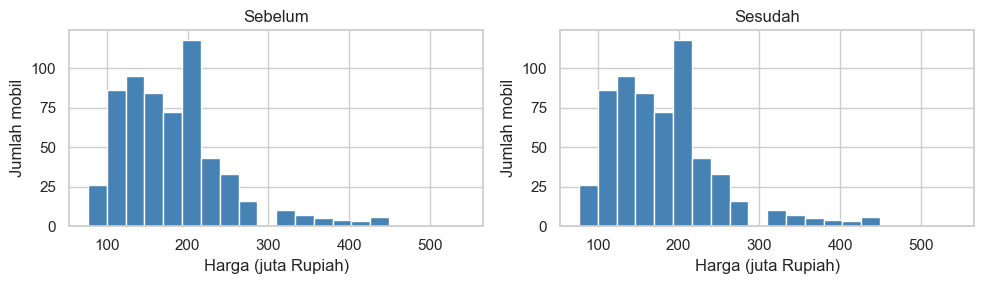

In [49]:
def quality(data):
    return pd.Series({
        "Jumlah baris": len(data),
        "Jumlah kolom": data.shape[1],
        "Missing aktual": int(data.isna().sum().sum()),
        "Duplikasi persis": int(data.duplicated().sum()),
        "Lokasi tidak diketahui": int(data["location"].str.lower().eq("unknown").sum())
    })

display(pd.DataFrame({"Sebelum": quality(raw), "Sesudah": quality(df)}))
display(pd.DataFrame({"Kategori sebelum": raw["location"].head(),
                      "Kategori sesudah": df["location"].head()}))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, data, title in zip(axes, [raw, df], ["Sebelum", "Sesudah"]):
    ax.hist(data[TARGET] / 1_000_000, bins=20, color="steelblue")
    ax.set(title=title, xlabel="Harga (juta Rupiah)", ylabel="Jumlah mobil")
plt.tight_layout()
plt.show()

## 13. Split train dan test
Gunakan 80% train dan 20% test dengan `random_state=42`. Ini mengasumsikan listing merupakan observasi independen. Identitas kendaraan dan waktu listing tidak tersedia untuk memeriksa kendaraan berulang atau membuat split waktu.

Cicilan dikeluarkan sejak awal karena waktu ketersediaannya belum jelas dan mungkin dihitung dari harga. Target tetap dalam Rupiah. Test disimpan untuk evaluasi model pada tahap berikutnya.

In [50]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=[TARGET, "instalment (Rp|Monthly)"])
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
print("Train:", X_train.shape, "Test:", X_test.shape)
assert set(X_train.index).isdisjoint(X_test.index)

Train: (487, 18) Test: (122, 18)


## 12. Preprocessing dan ketimpangan data
**Encoding** menggunakan One-Hot Encoding karena merek, keluarga model (`family`), lokasi, transmisi, dan tipe pelat merupakan kategori tanpa urutan. Kategori yang hanya muncul sekali di train dikelompokkan dengan `min_frequency=2` untuk mengurangi kolom sangat langka. Kategori baru di test ditangani oleh encoder.

**Scaling** menggunakan StandardScaler pada tahun, mileage, dan ukuran mesin (`engine`) karena rentangnya berbeda. Fitur biner sudah bernilai 0/1 sehingga cukup diimputasi modus. Semua parameter dipelajari dari train.

**Ketimpangan** diperiksa melalui jumlah merek dan rentang harga. Target berupa angka kontinu sehingga SMOTE klasifikasi tidak digunakan. Seluruh observasi valid dipertahankan karena oversampling merek sangat langka berisiko mengulang satu listing. Cross-validation digunakan untuk menilai kestabilan seleksi. Jumlah observasi per kelompok tetap ditampilkan agar keterbatasan representasi terlihat. Ini tidak menghilangkan bias sampel terhadap merek atau lokasi tertentu.

### 12.1 Feature engineering dari `car name`
Kolom `car name` memiliki ratusan kategori unik untuk jumlah baris yang kecil, sehingga One-Hot Encoding menghasilkan banyak kolom yang jarang muncul dan mudah overfit. Selain itu, ukuran mesin (misalnya 1.2, 1.5, 2.4) tersimpan sebagai teks di dalam nama mobil sehingga tidak dapat dipakai sebagai angka.

Kolom `car name` dipecah menjadi dua fitur:
- `family`: kata pertama nama mobil (misalnya `brio`, `pajero`, `fortuner`). Menjadi fitur kategorikal yang di-One-Hot Encoding.
- `engine`: angka terakhir pada nama mobil (ukuran mesin). Menjadi fitur numerik yang di-scale.

Transformasi ini hanya membaca teks pada tiap baris dan tidak memakai harga maupun statistik dari data lain, sehingga tidak menimbulkan kebocoran data dari test. Fungsi diterapkan pada train dan test secara terpisah. Kolom `car name` asli dikeluarkan karena informasinya sudah diwakili oleh `family` dan `engine`.


In [51]:
def tambah_fitur_nama_mobil(data):
    data = data.copy()
    token = data["car name"].str.split()
    data["family"] = token.str[0]
    data["engine"] = pd.to_numeric(token.str[-1], errors="coerce")
    return data.drop(columns=["car name"])

X_train = tambah_fitur_nama_mobil(X_train)
X_test = tambah_fitur_nama_mobil(X_test)

# Daftar kolom kategorikal disesuaikan: car name diganti family.
category_cols = [c for c in category_cols if c != "car name"] + ["family"]

print("Jumlah family unik (train):", X_train["family"].nunique())
print("Engine tidak terbaca (train, test):",
      int(X_train["engine"].isna().sum()), int(X_test["engine"].isna().sum()))
display(X_train[["family", "engine"]].head())


Jumlah family unik (train): 59
Engine tidak terbaca (train, test): 0 0


,family,engine
155,agya,1.200
247,ertiga,1.400
543,yaris,1.500
577,carry,1.500
153,eclipse,1.500


In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

display(X_train["brand"].value_counts().to_frame("Jumlah train"))
price_bins = [0, 150_000_000, 250_000_000, np.inf]
price_labels = ["<150 juta", "150–<250 juta", ">=250 juta"]
display(pd.cut(y_train, bins=price_bins, labels=price_labels, right=False)
        .value_counts(sort=False).to_frame("Jumlah train"))

def make_preprocessor(columns):
    num = [c for c in ["year", "mileage (km)", "engine"] if c in columns]
    cat = [c for c in category_cols if c in columns]
    binary = [c for c in binary_cols if c in columns]
    return ColumnTransformer([
        ("numerik", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num),
        ("kategori", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=2,
                                      sparse_output=False))
        ]), cat),
        ("biner", SimpleImputer(strategy="most_frequent"), binary)
    ], verbose_feature_names_out=False)

,Jumlah train
brand,
toyota,138
honda,116
daihatsu,69
mitsubishi,52
suzuki,48
nissan,28
wuling,15
mazda,11
datsun,4


,Jumlah train
price (Rp),
<150 juta,181
150–<250 juta,251
>=250 juta,55


## 14. Feature selection dengan alasan dan bukti
Pemilihan dilakukan dalam dua tahap. Pertama, cicilan dikeluarkan berdasarkan risiko leakage. Korelasi harga–cicilan ditampilkan hanya pada train sebagai bukti pendukung, bukan bukti pasti hubungan sebab-akibat.

Kedua, bandingkan fitur lengkap dengan kandidat tanpa `plate type` dan tanpa `location`. Keduanya mungkin menyimpan informasi pasar, sehingga keputusan membuangnya perlu diuji. Model Ridge sederhana digunakan sebagai alat pembanding dengan 5-fold cross-validation pada train. Seluruh preprocessing di-fit ulang di dalam masing-masing fold. Kandidat dengan rata-rata MAE terkecil dipilih. Pilihan ini bersifat awal dan bergantung pada model Ridge serta kandidat yang diuji.

Keluarga model (`family`), ukuran mesin (`engine`), dan merek membantu membedakan model dan segmen. Tahun, mileage, transmisi, serta perlengkapan berkaitan dengan karakteristik kendaraan. Fitur tersebut tetap dipakai sebagai kandidat meskipun korelasi tunggalnya kecil. Fitur baru yang dibuat hanya `family` dan `engine`, yang diturunkan dari teks `car name` pada bagian 12.1. Fitur berbasis tahun observasi atau satuan mileage tidak dibuat karena keduanya belum terkonfirmasi.

In [53]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import Ridge

train_audit = df.loc[X_train.index]
print("Korelasi harga–cicilan pada train:",
      train_audit[TARGET].corr(train_audit["instalment (Rp|Monthly)"]))
display(train_audit[["year", "mileage (km)"] + binary_cols + [TARGET]]
        .corr(method="spearman")[TARGET].drop(TARGET)
        .sort_values(ascending=False).to_frame("Korelasi Spearman train"))

candidates = {
    "Semua fitur aman": X_train.columns.tolist(),
    "Tanpa pelat": X_train.columns.drop("plate type").tolist(),
    "Tanpa pelat dan lokasi": X_train.columns.drop(["plate type", "location"]).tolist()
}
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
results = []
for name, columns in candidates.items():
    model = Pipeline([
        ("preprocessing", make_preprocessor(columns)),
        ("model", Ridge(alpha=10))
    ])
    mae = -cross_val_score(model, X_train[columns], y_train, cv=cv,
                          scoring="neg_mean_absolute_error")
    results.append({"Kandidat": name, "Jumlah fitur asli": len(columns),
                    "MAE CV (Rp)": mae.mean(), "Std MAE (Rp)": mae.std()})

comparison = pd.DataFrame(results).sort_values("MAE CV (Rp)")
display(comparison)
best_name = comparison.iloc[0]["Kandidat"]
selected_features = candidates[best_name]
print("Pilihan berdasarkan MAE CV:", best_name)
print("Fitur terpilih:", selected_features)

Korelasi harga–cicilan pada train: 0.9999978560920338


,Korelasi Spearman train
auto retract mirror,0.542
year,0.239
electric parking brake,0.193
vehicle stability control,0.180
auto cruise control,0.173
sun roof,0.172
keyless push start,0.095
rear camera,0.074
360 camera view,0.063
map navigator,0.051


,Kandidat,Jumlah fitur asli,MAE CV (Rp),Std MAE (Rp)
2,Tanpa pelat dan lokasi,17,"17,045,507.388","1,247,468.703"
1,Tanpa pelat,18,"17,339,825.904","1,323,305.191"
0,Semua fitur aman,19,"17,491,907.658","1,552,180.352"


Pilihan berdasarkan MAE CV: Tanpa pelat dan lokasi
Fitur terpilih: ['brand', 'year', 'mileage (km)', 'transmission', 'rear camera', 'sun roof', 'auto retract mirror', 'electric parking brake', 'map navigator', 'vehicle stability control', 'keyless push start', 'sports mode', '360 camera view', 'power sliding door', 'auto cruise control', 'family', 'engine']


In [54]:
decisions = []
for col in list(raw.columns) + ["family", "engine"]:
    if col == TARGET:
        status, reason = "Target", "Harga penawaran yang diprediksi"
    elif col == "instalment (Rp|Monthly)":
        status, reason = "Dibuang", "Potensi leakage; ketersediaan sebelum harga belum terverifikasi"
    elif col == "car name":
        status, reason = "Digantikan", "Dipecah menjadi family dan engine pada bagian 12.1 untuk mengurangi kardinalitas kategori"
    elif col in selected_features:
        status, reason = "Dipakai", "Termasuk kombinasi fitur dengan MAE CV terendah pada train"
    else:
        status, reason = "Dibuang", "Kombinasi tanpa fitur ini memperoleh MAE CV lebih rendah"
    decisions.append({"Fitur": col, "Keputusan": status, "Alasan": reason})
display(pd.DataFrame(decisions))

,Fitur,Keputusan,Alasan
0,car name,Digantikan,Dipecah menjadi family dan engine pada bagian ...
1,brand,Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...
2,year,Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...
3,mileage (km),Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...
4,location,Dibuang,Kombinasi tanpa fitur ini memperoleh MAE CV le...
5,transmission,Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...
6,plate type,Dibuang,Kombinasi tanpa fitur ini memperoleh MAE CV le...
7,rear camera,Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...
8,sun roof,Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...
9,auto retract mirror,Dipakai,Termasuk kombinasi fitur dengan MAE CV terenda...


## Hasil akhir yang siap untuk modeling
Fit preprocessing akhir pada seluruh train menggunakan fitur terpilih, lalu transform test. `X_train_ready`, `X_test_ready`, `y_train`, dan `y_test` siap digunakan untuk model berikutnya. Objek `preprocessor` perlu digunakan kembali ketika memproses data baru.

MAE pada tabel sebelumnya adalah hasil seleksi melalui cross-validation train. Evaluasi akhir pada test masih menjadi pekerjaan tahap modeling. Saat melakukan tuning model dengan cross-validation, gunakan Pipeline seperti contoh di atas supaya preprocessing kembali dilatih pada masing-masing fold.

In [55]:
preprocessor = make_preprocessor(selected_features)
train_values = preprocessor.fit_transform(X_train[selected_features])
test_values = preprocessor.transform(X_test[selected_features])
feature_names = preprocessor.get_feature_names_out()
X_train_ready = pd.DataFrame(train_values, columns=feature_names, index=X_train.index)
X_test_ready = pd.DataFrame(test_values, columns=feature_names, index=X_test.index)

display(pd.DataFrame({
    "Tahap": ["Train sebelum preprocessing", "Train sesudah preprocessing",
              "Test sebelum preprocessing", "Test sesudah preprocessing"],
    "Baris": [len(X_train), len(X_train_ready), len(X_test), len(X_test_ready)],
    "Kolom": [len(selected_features), X_train_ready.shape[1],
              len(selected_features), X_test_ready.shape[1]],
    "Missing": [X_train[selected_features].isna().sum().sum(),
                X_train_ready.isna().sum().sum(),
                X_test[selected_features].isna().sum().sum(),
                X_test_ready.isna().sum().sum()]
}))
assert np.isfinite(X_train_ready.to_numpy()).all()
assert np.isfinite(X_test_ready.to_numpy()).all()
assert X_train_ready.columns.equals(X_test_ready.columns)
display(X_train_ready.head())

,Tahap,Baris,Kolom,Missing
0,Train sebelum preprocessing,487,17,0
1,Train sesudah preprocessing,487,72,0
2,Test sebelum preprocessing,122,17,0
3,Test sesudah preprocessing,122,72,0


,year,mileage (km),engine,brand_daihatsu,brand_datsun,brand_honda,brand_hyundai,brand_mazda,brand_mitsubishi,brand_nissan,brand_suzuki,brand_toyota,brand_wuling,brand_infrequent_sklearn,transmission_automatic,transmission_manual,family_2,family_agya,family_almaz,family_avanza,family_ayla,family_baleno,family_br-v,family_brio,family_calya,family_carry,family_city,family_confero,family_cortez,family_cr-v,family_cx-3,family_cx-5,family_ertiga,family_fortuner,family_freed,family_go+,family_grand,family_hr-v,family_ignis,family_karimun,family_kijang,family_livina,family_march,family_mobilio,family_outlander,family_pajero,family_raize,family_rocky,family_rush,family_serena,family_sienta,family_sigra,family_sirion,family_sx4,family_terios,family_x-trail,family_xenia,family_xl7,family_xpander,family_yaris,family_infrequent_sklearn,rear camera,sun roof,auto retract mirror,electric parking brake,map navigator,vehicle stability control,keyless push start,sports mode,360 camera view,power sliding door,auto cruise control
155,1.946,-1.222,-0.793,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000
247,-0.519,-1.045,-0.142,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
543,1.453,-1.473,0.183,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000
577,1.453,-1.553,0.183,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
153,0.960,-0.608,0.183,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000


---

# Bagian 5 — Regression Modeling
## Prediksi Harga Mobil Bekas di Indonesia

Bagian ini melanjutkan proses dari Data Preparation pada bagian sebelumnya. Seluruh kode, output, dan penjelasan pada bagian 1–4 dipertahankan. Proses modeling ditambahkan setelah cell terakhir Data Preparation.

**Target prediksi:** `price (Rp)`.

**Model yang digunakan berdasarkan Modul 8 Linear Regression:**
1. **OLS / Linear Regression** sebagai model dasar tanpa regularisasi.
2. **Ridge Regression (L2)** untuk menyusutkan koefisien dan membantu menstabilkan model ketika fitur saling berkorelasi.
3. **Lasso Regression (L1)** untuk menyusutkan koefisien dan memungkinkan sebagian koefisien menjadi nol.

Model dibandingkan menggunakan **MSE, RMSE, dan R²**. Penentuan parameter Ridge dan Lasso dilakukan melalui 5-fold cross-validation pada data training. Data testing tidak digunakan untuk memilih model atau parameter.

Jalankan cell modeling secara berurutan dari atas ke bawah.


## 5.1 Pemilihan Model dan Alasan Penggunaan

Permasalahan penelitian merupakan **supervised learning dengan pendekatan regresi**, karena variabel target berupa harga mobil bekas dalam nilai numerik kontinu (Rupiah).

Ketiga model dipilih karena sesuai dengan materi Modul 8 dan memiliki fungsi pembanding yang berbeda:

| Model | Alasan penggunaan |
|---|---|
| OLS / Linear Regression | Menjadi baseline untuk mempelajari hubungan linear antara karakteristik mobil dan harga tanpa penalti koefisien. |
| Ridge Regression (L2) | Digunakan untuk mengendalikan besarnya koefisien ketika sejumlah fitur berpotensi saling berkorelasi, misalnya keluarga model (`family`) dan merek. |
| Lasso Regression (L1) | Digunakan untuk melihat apakah regularisasi dapat mengecilkan sebagian koefisien hingga nol sehingga model menjadi lebih sederhana. |

OLS menjadi acuan awal. Ridge dan Lasso digunakan untuk mengetahui apakah regularisasi dapat memperbaiki generalisasi model pada data testing. Pemilihan akhir tidak ditentukan berdasarkan asumsi bahwa salah satu model pasti paling baik, tetapi berdasarkan hasil cross-validation dan pemeriksaan metrik testing.

**Batasan pendekatan:** regresi linear mengasumsikan hubungan yang dapat didekati secara linear pada ruang fitur hasil preprocessing. Pola harga mobil bekas mungkin juga dipengaruhi interaksi dan hubungan non-linear. Karena itu, ketiga model ini diperlakukan sebagai model regresi awal sesuai materi praktikum.


## 5.2 Import Library Modeling

Library berikut diimpor pada bagian pertama kali diperlukan untuk modeling. Library preprocessing, `Ridge`, `KFold`, `cross_val_score`, `Pipeline`, NumPy, Pandas, Matplotlib, dan Seaborn sudah digunakan serta diimpor pada bagian sebelumnya sehingga tidak diimpor ulang.


In [56]:
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score


## 5.3 Memastikan Data Training dan Testing Siap Digunakan

Model menggunakan `X_train`, `X_test`, `y_train`, `y_test`, dan `selected_features` yang telah dibentuk pada bagian Data Preparation.

Pembagian data tidak dilakukan ulang. Dengan demikian, data training tetap berasal dari hasil split 80% dan data testing tetap berasal dari hasil split 20% dengan `random_state=42` pada bagian sebelumnya.

**Catatan preprocessing:** `X_train_ready` dan `X_test_ready` memang telah dibuat pada akhir Data Preparation. Namun, untuk cross-validation modeling, pipeline akan menerima data fitur sebelum preprocessing (`X_train`) dan menjalankan ulang preprocessing di dalam setiap fold. Cara ini mencegah parameter imputasi, encoding, dan scaling dari fold validasi ikut dipelajari ketika model dilatih pada fold training.


In [57]:
# Menggunakan kembali hasil split dan fitur terpilih dari Data Preparation.
X_train_model = X_train.loc[:, selected_features].copy()
X_test_model = X_test.loc[:, selected_features].copy()

# Pemeriksaan konsistensi data sebelum modeling.
assert X_train_model.columns.tolist() == selected_features
assert X_test_model.columns.tolist() == selected_features
assert len(X_train_model) == len(y_train)
assert len(X_test_model) == len(y_test)
assert set(X_train_model.index).isdisjoint(set(X_test_model.index))

print("Data siap digunakan untuk modeling.")
print("Jumlah data training :", X_train_model.shape[0])
print("Jumlah data testing  :", X_test_model.shape[0])
print("Jumlah fitur terpilih:", len(selected_features))
print("Random state         :", SEED)
print("\nDaftar fitur yang digunakan:")
display(pd.DataFrame({"Fitur": selected_features}))


Data siap digunakan untuk modeling.
Jumlah data training : 487
Jumlah data testing  : 122
Jumlah fitur terpilih: 17
Random state         : 42

Daftar fitur yang digunakan:


,Fitur
0,brand
1,year
2,mileage (km)
3,transmission
4,rear camera
5,sun roof
6,auto retract mirror
7,electric parking brake
8,map navigator
9,vehicle stability control


## 5.4 Menyiapkan Pipeline Modeling

Preprocessing yang telah didefinisikan pada bagian Data Preparation digunakan kembali melalui fungsi `make_preprocessor()`.

Setiap model dibungkus dalam `Pipeline` yang berisi:
1. `preprocessing`: imputasi, scaling fitur numerik, dan One-Hot Encoding fitur kategorikal.
2. `model`: algoritma regresi yang sedang dilatih.

Penggunaan pipeline penting pada cross-validation karena preprocessing akan di-fit hanya pada bagian training dari setiap fold, kemudian diterapkan pada fold validasi. Data testing akhir tetap tidak disentuh selama proses pemilihan parameter.


In [58]:
def make_model_pipeline(regression_model):
    return Pipeline(steps=[
        ("preprocessing", make_preprocessor(selected_features)),
        ("model", regression_model)
    ])

print("Pipeline modeling berhasil disiapkan.")
print("Preprocessing menggunakan fungsi make_preprocessor() dari Data Preparation.")


Pipeline modeling berhasil disiapkan.
Preprocessing menggunakan fungsi make_preprocessor() dari Data Preparation.


## 5.5 Menentukan Kandidat Parameter Regularisasi

OLS tidak memiliki parameter `alpha`. Ridge dan Lasso menggunakan `alpha` untuk mengatur kekuatan penalti regularisasi.

- `alpha` kecil berarti penalti lebih lemah.
- `alpha` besar berarti penalti lebih kuat.
- Penalti yang terlalu kuat dapat menyebabkan underfitting.
- Penalti yang terlalu lemah dapat membuat regularisasi kurang berpengaruh.

Kandidat `alpha` Ridge dicoba pada rentang logaritmik. Kandidat `alpha` Lasso ditentukan berdasarkan perkiraan `alpha_max` dari matriks fitur training yang telah dipreprocessing. Perhitungan tersebut hanya menggunakan data training, bukan data testing.

Nilai terbaik akan dipilih menggunakan 5-fold cross-validation dengan kriteria **MSE rata-rata terkecil**. Rentang kandidat merupakan ruang pencarian awal; apabila nilai terbaik berada di batas paling kecil atau paling besar, rentang parameter perlu ditinjau kembali.


In [59]:
# Kandidat alpha Ridge: rentang logaritmik.
ridge_alphas = np.logspace(-2, 5, 15)

# Perkiraan alpha maksimum Lasso dihitung hanya dari data training.
# X_train_ready berasal dari preprocessing yang telah di-fit pada X_train.
X_for_alpha = X_train_ready.to_numpy(dtype=float)
y_for_alpha = np.asarray(y_train, dtype=float)

X_centered = X_for_alpha - X_for_alpha.mean(axis=0)
y_centered = y_for_alpha - y_for_alpha.mean()

lasso_alpha_max = (
    np.max(np.abs(X_centered.T @ y_centered)) / len(y_for_alpha)
)

if not np.isfinite(lasso_alpha_max) or lasso_alpha_max <= 0:
    lasso_alpha_max = 1.0

lasso_alpha_min = max(lasso_alpha_max * 1e-4, np.finfo(float).eps)
lasso_alphas = np.geomspace(lasso_alpha_min, lasso_alpha_max, 15)

print("Kandidat alpha Ridge:")
display(pd.DataFrame({"alpha Ridge": ridge_alphas}))

print("\nRentang kandidat alpha Lasso:")
print(f"Alpha minimum: {lasso_alpha_min:,.4f}")
print(f"Alpha maksimum: {lasso_alpha_max:,.4f}")
display(pd.DataFrame({"alpha Lasso": lasso_alphas}))


Kandidat alpha Ridge:


,alpha Ridge
0,0.010
1,0.032
2,0.100
3,0.316
4,1.000
5,3.162
6,10.000
7,31.623
8,100.000
9,316.228



Rentang kandidat alpha Lasso:
Alpha minimum: 4,901.5715
Alpha maksimum: 49,015,715.1708


,alpha Lasso
0,"4,901.572"
1,"9,463.453"
2,"18,271.067"
3,"35,275.908"
4,"68,107.115"
5,"131,494.253"
6,"253,875.656"
7,"490,157.152"
8,"946,345.300"
9,"1,827,106.721"


## 5.6 Melatih Model OLS, Ridge, dan Lasso

Ketiga model menggunakan fitur dan pembagian data training yang sama.

**OLS**
- Menggunakan `LinearRegression`.
- Tidak menggunakan penalti regularisasi.
- Dievaluasi dengan 5-fold cross-validation sebagai baseline.

**Ridge**
- Menggunakan `Ridge`.
- Kandidat `alpha` diuji menggunakan `GridSearchCV`.
- Parameter terbaik dipilih berdasarkan MSE cross-validation terkecil.

**Lasso**
- Menggunakan `Lasso`.
- Kandidat `alpha` diuji menggunakan `GridSearchCV`.
- `max_iter` ditingkatkan agar optimasi memiliki kesempatan untuk konvergen.
- Parameter terbaik dipilih berdasarkan MSE cross-validation terkecil.

Objek `cv` yang digunakan adalah 5-fold `KFold` dengan `shuffle=True` dan `random_state=SEED`, yang telah dibuat pada bagian Feature Selection. Dengan demikian, proses pembagian fold dapat direproduksi.


In [60]:
# OLS: baseline tanpa regularisasi.
ols_pipeline = make_model_pipeline(LinearRegression())

ols_cv_scores = -cross_val_score(
    ols_pipeline,
    X_train_model,
    y_train,
    cv=cv,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

ols_pipeline.fit(X_train_model, y_train)

# Ridge: pencarian alpha menggunakan GridSearchCV.
ridge_search = GridSearchCV(
    estimator=make_model_pipeline(Ridge()),
    param_grid={"model__alpha": ridge_alphas},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

ridge_search.fit(X_train_model, y_train)

# Lasso: pencarian alpha menggunakan GridSearchCV.
lasso_search = GridSearchCV(
    estimator=make_model_pipeline(
        Lasso(max_iter=100000, tol=1e-4, selection="cyclic")
    ),
    param_grid={"model__alpha": lasso_alphas},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

lasso_search.fit(X_train_model, y_train)

# Model final yang telah dilatih pada seluruh data training.
model_pipelines = {
    "OLS": ols_pipeline,
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_
}

print("Training ketiga model selesai.")


Training ketiga model selesai.


## 5.7 Menampilkan Hasil Cross-Validation dan Parameter Terpilih

Tabel berikut merangkum performa cross-validation serta parameter regularisasi terbaik.

- OLS tidak memiliki nilai `alpha`.
- Ridge dan Lasso menampilkan `alpha` yang menghasilkan MSE cross-validation terkecil.
- `CV RMSE` merupakan akar dari rata-rata CV MSE sehingga memiliki satuan yang sama dengan target, yaitu Rupiah.
- `Std CV MSE` menunjukkan variasi skor MSE antar-fold.

Tabel diurutkan berdasarkan CV MSE terkecil. Model dengan CV MSE terkecil menjadi kandidat utama sebelum hasil testing diperiksa.


In [61]:
ols_cv_mse_mean = float(np.mean(ols_cv_scores))
ols_cv_mse_std = float(np.std(ols_cv_scores, ddof=1))

ridge_best_index = ridge_search.best_index_
ridge_cv_mse_mean = float(-ridge_search.best_score_)
ridge_cv_mse_std = float(ridge_search.cv_results_["std_test_score"][ridge_best_index])

lasso_best_index = lasso_search.best_index_
lasso_cv_mse_mean = float(-lasso_search.best_score_)
lasso_cv_mse_std = float(lasso_search.cv_results_["std_test_score"][lasso_best_index])

cv_model_results = pd.DataFrame([
    {
        "Model": "OLS",
        "Alpha Terbaik": np.nan,
        "CV MSE": ols_cv_mse_mean,
        "Std CV MSE": ols_cv_mse_std,
        "CV RMSE": np.sqrt(ols_cv_mse_mean)
    },
    {
        "Model": "Ridge",
        "Alpha Terbaik": ridge_search.best_params_["model__alpha"],
        "CV MSE": ridge_cv_mse_mean,
        "Std CV MSE": ridge_cv_mse_std,
        "CV RMSE": np.sqrt(ridge_cv_mse_mean)
    },
    {
        "Model": "Lasso",
        "Alpha Terbaik": lasso_search.best_params_["model__alpha"],
        "CV MSE": lasso_cv_mse_mean,
        "Std CV MSE": lasso_cv_mse_std,
        "CV RMSE": np.sqrt(lasso_cv_mse_mean)
    }
]).sort_values("CV MSE").reset_index(drop=True)

print("Parameter terbaik Ridge:", ridge_search.best_params_)
print("Parameter terbaik Lasso:", lasso_search.best_params_)
display(cv_model_results.style.format({
    "Alpha Terbaik": "{:,.4f}",
    "CV MSE": "{:,.2f}",
    "Std CV MSE": "{:,.2f}",
    "CV RMSE": "{:,.2f}"
}))


Parameter terbaik Ridge: {'model__alpha': np.float64(1.0)}
Parameter terbaik Lasso: {'model__alpha': np.float64(131494.25299132266)}


,Model,Alpha Terbaik,CV MSE,Std CV MSE,CV RMSE
0,Ridge,1.0000,"663,531,463,331,431.88","179,291,669,945,024.25","25,759,104.47"
1,Lasso,"131,494.2530","745,325,004,455,481.75","213,211,398,031,905.59","27,300,641.10"
2,OLS,nan,"1,034,208,458,625,002.62","435,697,430,471,266.25","32,159,111.60"


## 5.8 Membuat Prediksi pada Data Training dan Testing

Setelah proses training dan pemilihan parameter selesai, ketiga model digunakan untuk menghasilkan prediksi.

- Prediksi training digunakan untuk melihat kecocokan model terhadap data yang dipelajari.
- Prediksi testing digunakan untuk mengukur kemampuan model pada data yang tidak digunakan saat training.

Data testing hanya digunakan pada tahap evaluasi ini. Hasil testing tidak digunakan untuk mengubah parameter atau memilih ulang model.


In [62]:
# Membuat prediksi dari ketiga model.
model_predictions = {}
model_metric_rows = []

def calculate_regression_metrics(actual, predicted):
    mse_value = mean_squared_error(actual, predicted)
    rmse_value = np.sqrt(mse_value)
    r2_value = r2_score(actual, predicted)
    return mse_value, rmse_value, r2_value

for model_name, fitted_pipeline in model_pipelines.items():
    train_prediction = fitted_pipeline.predict(X_train_model)
    test_prediction = fitted_pipeline.predict(X_test_model)

    model_predictions[model_name] = {
        "train": train_prediction,
        "test": test_prediction
    }

    train_mse, train_rmse, train_r2 = calculate_regression_metrics(
        y_train, train_prediction
    )
    test_mse, test_rmse, test_r2 = calculate_regression_metrics(
        y_test, test_prediction
    )

    cv_row = cv_model_results.loc[
        cv_model_results["Model"] == model_name
    ].iloc[0]

    model_metric_rows.append({
        "Model": model_name,
        "Alpha Terbaik": cv_row["Alpha Terbaik"],
        "CV MSE": cv_row["CV MSE"],
        "Train MSE": train_mse,
        "Train RMSE": train_rmse,
        "Train R2": train_r2,
        "Test MSE": test_mse,
        "Test RMSE": test_rmse,
        "Test R2": test_r2
    })

print("Prediksi untuk data training dan testing berhasil dibuat.")


Prediksi untuk data training dan testing berhasil dibuat.


## 5.9 Evaluasi dan Perbandingan Hasil Modeling

Evaluasi menggunakan tiga metrik sesuai Modul 8:

1. **Mean Squared Error (MSE):** rata-rata kuadrat selisih harga aktual dan prediksi. Nilai yang lebih kecil menunjukkan kesalahan kuadrat yang lebih rendah. Satuannya adalah Rupiah kuadrat.
2. **Root Mean Squared Error (RMSE):** akar dari MSE. Nilainya berada pada skala Rupiah sehingga lebih mudah diinterpretasikan sebagai besarnya kesalahan prediksi.
3. **R-squared (R²):** proporsi variasi harga yang dapat dijelaskan model. Nilai yang semakin mendekati 1 menunjukkan kemampuan penjelasan yang lebih tinggi. Nilai negatif pada data testing berarti model lebih buruk daripada baseline yang selalu memprediksi rata-rata harga data training.

Metrik training dan testing ditampilkan bersama untuk melihat perbedaan performa. Kandidat utama tetap ditentukan berdasarkan CV MSE, bukan dengan memilih model yang kebetulan memperoleh skor testing terbaik.


In [63]:
model_comparison = (
    pd.DataFrame(model_metric_rows)
    .sort_values("CV MSE")
    .reset_index(drop=True)
)

display(model_comparison.style.format({
    "Alpha Terbaik": "{:,.4f}",
    "CV MSE": "{:,.2f}",
    "Train MSE": "{:,.2f}",
    "Train RMSE": "Rp{:,.0f}",
    "Train R2": "{:.4f}",
    "Test MSE": "{:,.2f}",
    "Test RMSE": "Rp{:,.0f}",
    "Test R2": "{:.4f}"
}))

best_model_name = model_comparison.iloc[0]["Model"]
best_model = model_pipelines[best_model_name]
best_prediction = model_predictions[best_model_name]["test"]

print("\nKandidat utama berdasarkan CV MSE:", best_model_name)


,Model,Alpha Terbaik,CV MSE,Train MSE,Train RMSE,Train R2,Test MSE,Test RMSE,Test R2
0,Ridge,1.0000,"663,531,463,331,431.88","364,078,937,181,805.62","Rp19,080,853",0.9149,"678,094,391,950,725.75","Rp26,040,246",0.8674
1,Lasso,"131,494.2530","745,325,004,455,481.75","425,285,230,903,702.56","Rp20,622,445",0.9006,"761,781,325,932,967.00","Rp27,600,386",0.8511
2,OLS,nan,"1,034,208,458,625,002.62","326,591,932,558,392.88","Rp18,071,855",0.9237,"567,198,017,505,063.50","Rp23,815,919",0.8891



Kandidat utama berdasarkan CV MSE: Ridge


## 5.10 Menampilkan Contoh Hasil Prediksi

Tabel berikut membandingkan harga aktual dan harga prediksi pada sebagian data testing dari setiap model.

Residual dihitung dengan rumus:

`Residual = Harga Aktual - Harga Prediksi`

- Residual positif berarti model memprediksi harga terlalu rendah.
- Residual negatif berarti model memprediksi harga terlalu tinggi.
- Absolute Error menunjukkan besar kesalahan tanpa memperhatikan arah kesalahan.


In [64]:
prediction_comparison = pd.DataFrame(index=y_test.index)
prediction_comparison["Harga Aktual (Rp)"] = y_test

for model_name in model_pipelines:
    prediction_comparison[f"Prediksi {model_name} (Rp)"] = (
        model_predictions[model_name]["test"]
    )

prediction_comparison[f"Residual {best_model_name} (Rp)"] = (
    prediction_comparison["Harga Aktual (Rp)"]
    - prediction_comparison[f"Prediksi {best_model_name} (Rp)"]
)
prediction_comparison[f"Absolute Error {best_model_name} (Rp)"] = (
    prediction_comparison[f"Residual {best_model_name} (Rp)"].abs()
)

display(prediction_comparison.head(10))


,Harga Aktual (Rp),Prediksi OLS (Rp),Prediksi Ridge (Rp),Prediksi Lasso (Rp),Residual Ridge (Rp),Absolute Error Ridge (Rp)
291,282000000,"268,700,449.216","267,540,992.380","262,254,556.560","14,459,007.620","14,459,007.620"
365,144000000,"153,612,910.949","153,721,246.079","150,407,067.546","-9,721,246.079","9,721,246.079"
467,192000000,"196,661,635.989","194,334,289.129","197,989,208.249","-2,334,289.129","2,334,289.129"
567,118000000,"109,054,059.050","109,067,001.352","109,125,577.810","8,932,998.648","8,932,998.648"
118,191000000,"211,597,008.271","209,409,617.365","202,257,114.898","-18,409,617.365","18,409,617.365"
265,209000000,"214,296,375.581","212,523,379.034","215,181,019.924","-3,523,379.034","3,523,379.034"
82,117000000,"120,251,699.311","122,276,432.148","124,715,311.195","-5,276,432.148","5,276,432.148"
137,240000000,"235,364,771.672","235,955,415.997","233,142,833.014","4,044,584.003","4,044,584.003"
539,213000000,"214,825,061.681","215,165,106.869","212,663,493.678","-2,165,106.869","2,165,106.869"
140,95000000,"78,084,073.901","70,866,879.171","67,619,331.981","24,133,120.829","24,133,120.829"


## 5.11 Visualisasi Harga Aktual dan Prediksi

Scatterplot membandingkan harga aktual dan harga prediksi pada data testing. Garis diagonal merupakan garis prediksi ideal (`aktual = prediksi`).

Titik yang semakin dekat dengan garis diagonal menunjukkan hasil prediksi yang semakin dekat dengan harga aktual. Sebaran titik yang jauh dari garis menunjukkan kesalahan prediksi yang lebih besar.

`seaborn.regplot` ditambahkan untuk memperlihatkan kecenderungan hubungan antara harga aktual dan prediksi. Regplot ini merupakan visualisasi diagnostik, bukan pengganti evaluasi metrik model multivariat.


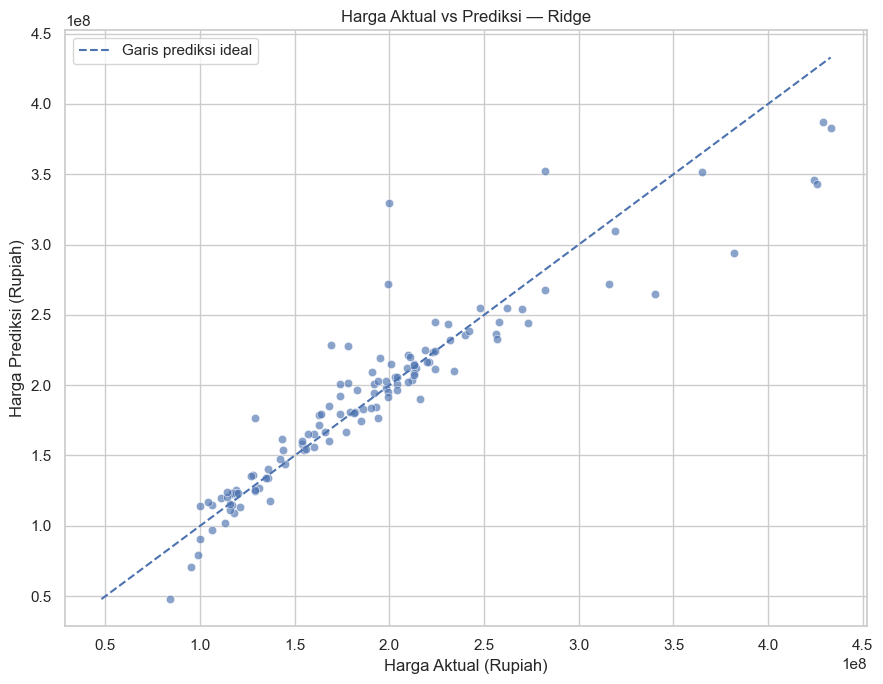

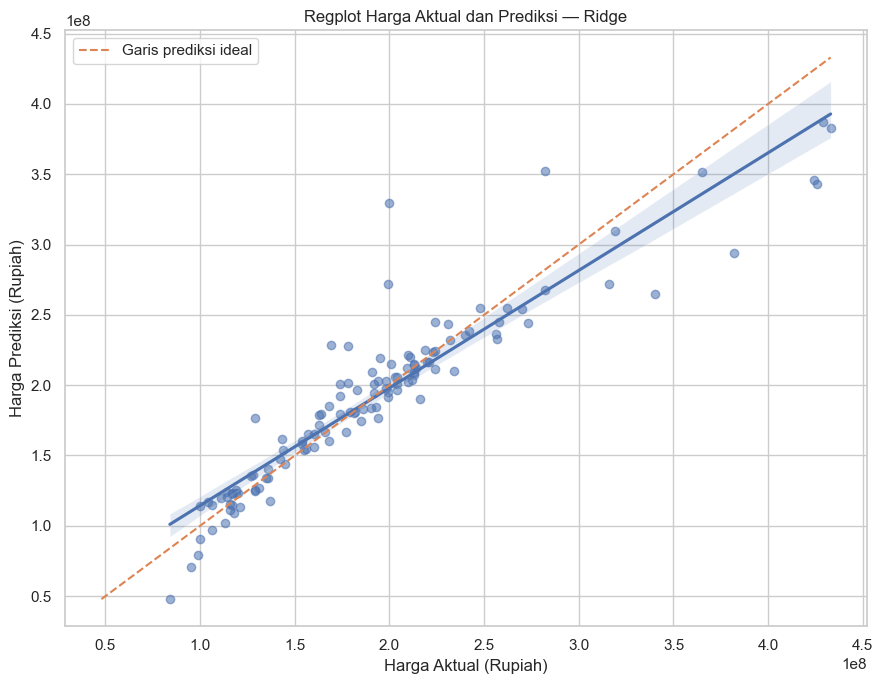

In [65]:
actual_values = np.asarray(y_test, dtype=float)
predicted_values = np.asarray(best_prediction, dtype=float)

plot_min = min(actual_values.min(), predicted_values.min())
plot_max = max(actual_values.max(), predicted_values.max())

plt.figure(figsize=(9, 7))
sns.scatterplot(
    x=actual_values,
    y=predicted_values,
    alpha=0.65
)
plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--",
    label="Garis prediksi ideal"
)
plt.title(f"Harga Aktual vs Prediksi — {best_model_name}")
plt.xlabel("Harga Aktual (Rupiah)")
plt.ylabel("Harga Prediksi (Rupiah)")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 7))
sns.regplot(
    x=actual_values,
    y=predicted_values,
    ci=95,
    scatter_kws={"alpha": 0.55}
)
plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--",
    label="Garis prediksi ideal"
)
plt.title(f"Regplot Harga Aktual dan Prediksi — {best_model_name}")
plt.xlabel("Harga Aktual (Rupiah)")
plt.ylabel("Harga Prediksi (Rupiah)")
plt.legend()
plt.tight_layout()
plt.show()


## 5.12 Analisis Residual Model

Residual merupakan selisih antara harga aktual dan harga prediksi. Pemeriksaan residual membantu melihat apakah kesalahan prediksi tersebar secara acak atau menunjukkan pola tertentu.

- Residual yang tersebar di sekitar nol tanpa pola yang jelas lebih mendukung kecocokan model linear.
- Pola melengkung dapat mengindikasikan hubungan yang belum tertangkap model linear.
- Sebaran residual yang semakin lebar pada harga prediksi yang lebih tinggi dapat mengindikasikan varians kesalahan yang tidak konstan.
- Distribusi residual yang tidak simetris dapat menunjukkan adanya kesalahan prediksi ekstrem atau pengaruh distribusi target yang menceng.

Pemeriksaan ini merupakan diagnosis awal dan tidak otomatis membuktikan terpenuhi atau tidaknya seluruh asumsi regresi.


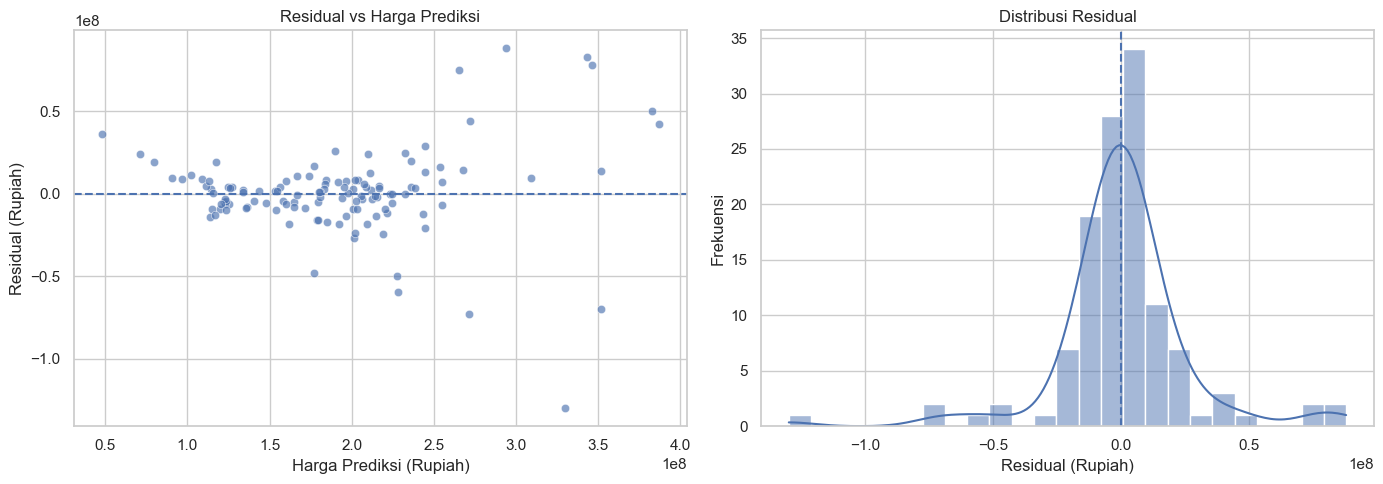

count            122.000
mean         593,488.746
std       26,140,836.596
min     -129,849,281.833
25%       -8,393,114.126
50%          770,252.075
75%        8,302,180.830
max       87,920,454.233
Name: Residual (Rp), dtype: float64

In [66]:
best_residual = actual_values - predicted_values

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    x=predicted_values,
    y=best_residual,
    alpha=0.65,
    ax=axes[0]
)
axes[0].axhline(0, linestyle="--")
axes[0].set_title("Residual vs Harga Prediksi")
axes[0].set_xlabel("Harga Prediksi (Rupiah)")
axes[0].set_ylabel("Residual (Rupiah)")

sns.histplot(
    best_residual,
    bins=25,
    kde=True,
    ax=axes[1]
)
axes[1].axvline(0, linestyle="--")
axes[1].set_title("Distribusi Residual")
axes[1].set_xlabel("Residual (Rupiah)")
axes[1].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

display(pd.Series(best_residual, name="Residual (Rp)").describe())


## 5.13 Membandingkan Koefisien OLS, Ridge, dan Lasso

Perbandingan koefisien digunakan untuk melihat pengaruh regularisasi terhadap besar koefisien fitur.

- OLS mengestimasi koefisien tanpa penalti.
- Ridge cenderung menyusutkan koefisien ke arah nol, tetapi tidak melakukan seleksi fitur dengan membuat koefisien tepat nol.
- Lasso dapat membuat sebagian koefisien menjadi nol.

Koefisien diambil dari pipeline yang telah dilatih menggunakan seluruh data training. Nama fitur berasal dari hasil preprocessing masing-masing pipeline. Grafik dibatasi pada 20 fitur dengan nilai absolut koefisien terbesar agar mudah dibaca.


In [67]:
coefficient_series = []

for model_name, fitted_pipeline in model_pipelines.items():
    fitted_preprocessor = fitted_pipeline.named_steps["preprocessing"]
    fitted_estimator = fitted_pipeline.named_steps["model"]

    transformed_feature_names = fitted_preprocessor.get_feature_names_out()
    coefficients = np.asarray(fitted_estimator.coef_).ravel()

    coefficient_series.append(
        pd.Series(
            coefficients,
            index=transformed_feature_names,
            name=model_name
        )
    )

coefficient_comparison = pd.concat(coefficient_series, axis=1).reset_index()
coefficient_comparison = coefficient_comparison.rename(
    columns={"index": "Fitur"}
)

coefficient_comparison["Nilai Absolut Maksimum"] = (
    coefficient_comparison[["OLS", "Ridge", "Lasso"]]
    .abs()
    .max(axis=1)
)

top_coefficient_features = (
    coefficient_comparison
    .sort_values("Nilai Absolut Maksimum", ascending=False)
    .head(20)
)

display(top_coefficient_features)


,Fitur,OLS,Ridge,Lasso,Nilai Absolut Maksimum
45,family_pajero,"145,962,316.981","83,699,981.193","78,763,859.595","145,962,316.981"
33,family_fortuner,"125,764,949.625","64,040,118.431","46,480,573.036","125,764,949.625"
25,family_carry,"-73,763,798.200","-61,682,842.907","-68,011,879.028","73,763,798.200"
29,family_cr-v,"69,249,667.609","55,463,766.435","60,645,372.239","69,249,667.609"
6,brand_hyundai,"68,103,715.483","43,434,350.549","36,286,978.776","68,103,715.483"
31,family_cx-5,"63,986,990.283","14,054,520.804",0.000,"63,986,990.283"
4,brand_datsun,"-61,349,860.235","-33,901,697.351","-25,675,624.700","61,349,860.235"
17,family_agya,"-61,228,322.608","-38,082,166.454","-21,664,328.383","61,228,322.608"
24,family_calya,"-60,490,373.829","-39,419,455.562","-24,861,010.116","60,490,373.829"
49,family_serena,"58,115,309.515","31,623,366.132","1,179,961.275","58,115,309.515"


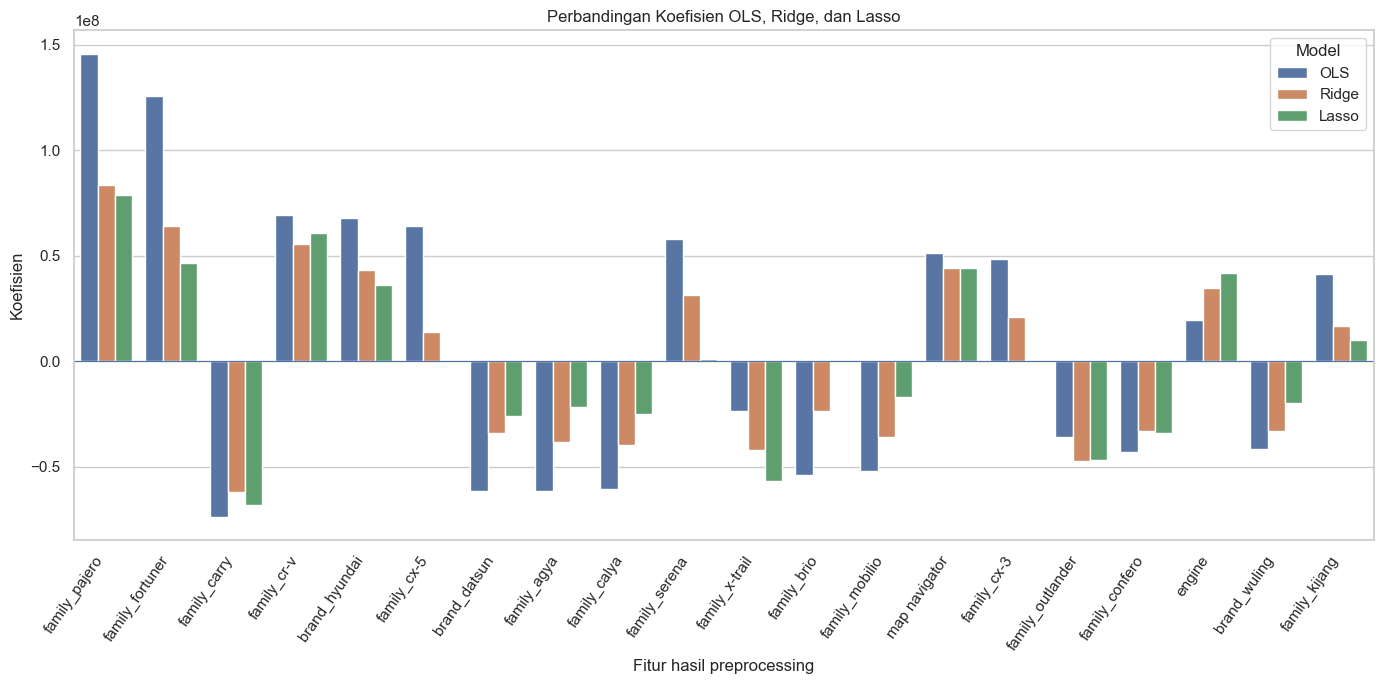

Koefisien Lasso yang bernilai nol atau sangat mendekati nol: 29 dari 72 fitur.


In [68]:
coefficient_long = top_coefficient_features.melt(
    id_vars="Fitur",
    value_vars=["OLS", "Ridge", "Lasso"],
    var_name="Model",
    value_name="Koefisien"
)

plt.figure(figsize=(14, 7))
sns.barplot(
    data=coefficient_long,
    x="Fitur",
    y="Koefisien",
    hue="Model"
)
plt.axhline(0, linewidth=0.8)
plt.xticks(rotation=55, ha="right")
plt.title("Perbandingan Koefisien OLS, Ridge, dan Lasso")
plt.xlabel("Fitur hasil preprocessing")
plt.ylabel("Koefisien")
plt.tight_layout()
plt.show()

lasso_zero_count = int(
    (np.abs(coefficient_comparison["Lasso"]) <= 1e-10).sum()
)
print(
    f"Koefisien Lasso yang bernilai nol atau sangat mendekati nol: "
    f"{lasso_zero_count} dari {len(coefficient_comparison)} fitur."
)


## 5.14 Interpretasi Hasil Awal Modeling

Model utama dipilih berdasarkan CV MSE terkecil pada data training. Hasil testing digunakan untuk melihat kemampuan generalisasi model pada data yang tidak digunakan selama pelatihan.

Interpretasi perlu mencakup:
1. Model dengan CV MSE terendah.
2. Perbandingan MSE, RMSE, dan R² pada data testing.
3. Perbedaan RMSE training dan testing sebagai indikasi awal overfitting.
4. Pola sebaran aktual dan prediksi.
5. Pola residual.
6. Perubahan koefisien setelah Ridge dan Lasso diterapkan.

**Catatan interpretasi R²:** R² sebesar 0,60 berarti sekitar 60% variasi target pada data evaluasi dapat dijelaskan oleh model. R² bukan berarti model memiliki akurasi prediksi sebesar 60%.


In [69]:
best_result = model_comparison.iloc[0]

print("RINGKASAN HASIL MODELING")
print("=" * 60)
print(f"Kandidat utama berdasarkan CV MSE : {best_result['Model']}")
print(f"CV MSE                            : {best_result['CV MSE']:,.2f}")
print(f"Test MSE                          : {best_result['Test MSE']:,.2f}")
print(f"Test RMSE                         : Rp{best_result['Test RMSE']:,.0f}")
print(f"Test R2                           : {best_result['Test R2']:.4f}")

if best_result["Test R2"] >= 0:
    explained_variation = best_result["Test R2"] * 100
    print(
        f"Interpretasi R2                   : sekitar {explained_variation:.2f}% "
        "variasi harga pada data testing dapat dijelaskan oleh model."
    )
else:
    print(
        "Interpretasi R2                   : nilai negatif menunjukkan "
        "performa lebih buruk daripada baseline rata-rata pada data testing."
    )

train_rmse = best_result["Train RMSE"]
test_rmse = best_result["Test RMSE"]

if train_rmse > 0:
    rmse_ratio = test_rmse / train_rmse
    print(f"Rasio Test RMSE / Train RMSE       : {rmse_ratio:.3f}")
    print(
        "Rasio tersebut perlu dibaca bersama tabel metrik dan grafik residual "
        "untuk menilai indikasi overfitting."
    )

print("\nGunakan tabel perbandingan, grafik aktual-prediksi, dan residual "
      "untuk menyusun kesimpulan akhir.")


RINGKASAN HASIL MODELING
Kandidat utama berdasarkan CV MSE : Ridge
CV MSE                            : 663,531,463,331,431.88
Test MSE                          : 678,094,391,950,725.75
Test RMSE                         : Rp26,040,246
Test R2                           : 0.8674
Interpretasi R2                   : sekitar 86.74% variasi harga pada data testing dapat dijelaskan oleh model.
Rasio Test RMSE / Train RMSE       : 1.365
Rasio tersebut perlu dibaca bersama tabel metrik dan grafik residual untuk menilai indikasi overfitting.

Gunakan tabel perbandingan, grafik aktual-prediksi, dan residual untuk menyusun kesimpulan akhir.


In [70]:
# Menyusun draf kesimpulan 5.15 otomatis dari output aktual (tidak ada angka yang diketik manual).
import textwrap

hasil = model_comparison.copy()
utama = hasil.iloc[0]                                  # kandidat utama menurut CV MSE
nama_utama = utama["Model"]
terbaik_test = hasil.sort_values("Test RMSE").iloc[0]["Model"]

r2 = utama["Test R2"]
if r2 >= 0.8:
    tingkat_r2 = "tinggi"
elif r2 >= 0.5:
    tingkat_r2 = "sedang"
elif r2 >= 0:
    tingkat_r2 = "rendah"
else:
    tingkat_r2 = "lebih buruk daripada baseline rata-rata"

rasio = utama["Test RMSE"] / utama["Train RMSE"]
if rasio < 1.1:
    teks_overfit = "selisih RMSE training dan testing kecil sehingga tidak ada indikasi overfitting yang kuat"
elif rasio < 1.3:
    teks_overfit = "RMSE testing sedikit lebih besar daripada RMSE training sehingga ada indikasi overfitting ringan"
else:
    teks_overfit = "RMSE testing jauh lebih besar daripada RMSE training sehingga ada indikasi overfitting"

rmse_semua = hasil["Test RMSE"]
selisih_model = (rmse_semua.max() - rmse_semua.min()) / rmse_semua.min() * 100
if selisih_model < 5:
    teks_banding = (f"Ketiga model menghasilkan Test RMSE yang sangat berdekatan (selisih {selisih_model:.1f}%), "
                    "sehingga regularisasi tidak memberi perbaikan yang berarti pada data ini")
else:
    teks_banding = (f"Test RMSE antar-model berbeda sekitar {selisih_model:.1f}%, "
                    f"dengan Test RMSE terkecil dimiliki model {terbaik_test}")

# Pola residual model utama
rata_residual = float(np.mean(best_residual))
korelasi_lebar = float(pd.Series(predicted_values).corr(pd.Series(np.abs(best_residual)), method="spearman"))
kemiringan = float(pd.Series(best_residual).skew())
teks_residual = (
    f"rata-rata residual sebesar Rp{rata_residual:,.0f} "
    f"({'prediksi cenderung terlalu rendah' if rata_residual > 0 else 'prediksi cenderung terlalu tinggi'}), "
    f"korelasi Spearman antara harga prediksi dan besar residual {korelasi_lebar:.2f} "
    f"({'kesalahan melebar pada harga yang lebih tinggi' if korelasi_lebar > 0.3 else 'tidak tampak pelebaran kesalahan yang kuat'}), "
    f"dan kemiringan distribusi residual {kemiringan:.2f} "
    f"({'cukup menceng sehingga terdapat kesalahan ekstrem' if abs(kemiringan) > 0.5 else 'relatif simetris'})"
)

teks_lasso = (f"Lasso membuat {lasso_zero_count} dari {len(coefficient_comparison)} koefisien menjadi nol atau "
              "mendekati nol")

paragraf = (
    "Pemodelan harga mobil bekas dilakukan menggunakan tiga algoritma regresi, yaitu OLS, Ridge Regression, "
    "dan Lasso Regression. OLS digunakan sebagai model dasar, sedangkan Ridge dan Lasso digunakan untuk menguji "
    "pengaruh regularisasi terhadap performa model. Penentuan parameter Ridge dan Lasso dilakukan melalui 5-fold "
    "cross-validation pada data training.\n\n"
    f"Berdasarkan hasil cross-validation, model {nama_utama} memperoleh CV MSE terendah sebesar {utama['CV MSE']:,.2f}"
    + (f" dengan alpha {utama['Alpha Terbaik']:,.4f}" if pd.notna(utama["Alpha Terbaik"]) else "")
    + f". Pada data testing, model tersebut menghasilkan MSE sebesar {utama['Test MSE']:,.2f}, "
    f"RMSE sebesar Rp{utama['Test RMSE']:,.0f}, dan R² sebesar {r2:.4f}. Hasil tersebut menunjukkan bahwa "
    f"kemampuan model menjelaskan variasi harga pada data testing tergolong {tingkat_r2}"
    + (f" (sekitar {r2*100:.1f}% variasi harga terjelaskan)" if r2 >= 0 else "")
    + f", dengan rasio Test RMSE terhadap Train RMSE {rasio:.3f}; {teks_overfit}. "
    f"{teks_banding}. {teks_lasso}.\n\n"
    f"Pemeriksaan residual memperlihatkan bahwa {teks_residual}. "
    f"Dengan demikian, model {nama_utama} menjadi kandidat utama pada tahap modeling ini, dengan mempertimbangkan "
    "keterbatasan jumlah observasi, distribusi harga yang menceng, potensi bias sampel (dominasi Jabodetabek dan "
    "merek tertentu), harga yang merupakan harga penawaran, serta asumsi hubungan linear."
)
if nama_utama != terbaik_test:
    paragraf += (f"\n\nCatatan: model dengan Test RMSE terkecil adalah {terbaik_test}, bukan {nama_utama}. "
                 "Pemilihan tetap mengikuti CV MSE agar data testing tidak dipakai untuk memilih model.")

print("DRAF KESIMPULAN SEMENTARA MODELING (5.15)")
print("=" * 60)
for bagian in paragraf.split("\n\n"):
    print(textwrap.fill(bagian, width=100))
    print()


DRAF KESIMPULAN SEMENTARA MODELING (5.15)
Pemodelan harga mobil bekas dilakukan menggunakan tiga algoritma regresi, yaitu OLS, Ridge
Regression, dan Lasso Regression. OLS digunakan sebagai model dasar, sedangkan Ridge dan Lasso
digunakan untuk menguji pengaruh regularisasi terhadap performa model. Penentuan parameter Ridge dan
Lasso dilakukan melalui 5-fold cross-validation pada data training.

Berdasarkan hasil cross-validation, model Ridge memperoleh CV MSE terendah sebesar
663,531,463,331,431.88 dengan alpha 1.0000. Pada data testing, model tersebut menghasilkan MSE
sebesar 678,094,391,950,725.75, RMSE sebesar Rp26,040,246, dan R² sebesar 0.8674. Hasil tersebut
menunjukkan bahwa kemampuan model menjelaskan variasi harga pada data testing tergolong tinggi
(sekitar 86.7% variasi harga terjelaskan), dengan rasio Test RMSE terhadap Train RMSE 1.365; RMSE
testing jauh lebih besar daripada RMSE training sehingga ada indikasi overfitting. Test RMSE antar-
model berbeda sekitar 15.9%, denga

## 5.15 Kesimpulan Sementara Modeling

Lengkapi kesimpulan berdasarkan output aktual setelah seluruh cell dijalankan. Jangan mengisi nilai metrik berdasarkan perkiraan.

**Template narasi:**

Pemodelan harga mobil bekas dilakukan menggunakan tiga algoritma regresi, yaitu OLS, Ridge Regression, dan Lasso Regression. OLS digunakan sebagai model dasar, sedangkan Ridge dan Lasso digunakan untuk menguji pengaruh regularisasi terhadap performa model. Penentuan parameter Ridge dan Lasso dilakukan melalui 5-fold cross-validation pada data training.

Berdasarkan hasil cross-validation, model __________ memperoleh CV MSE terendah sebesar __________. Pada data testing, model tersebut menghasilkan MSE sebesar __________, RMSE sebesar __________, dan R² sebesar __________. Hasil tersebut menunjukkan bahwa __________. Pemeriksaan residual memperlihatkan __________. Dengan demikian, model __________ menjadi kandidat utama pada tahap modeling ini, dengan mempertimbangkan keterbatasan jumlah observasi, distribusi harga, potensi bias sampel, serta asumsi hubungan linear.

**Pemetaan terhadap kriteria Progress 3:**

| Kriteria penilaian | Bagian notebook |
|---|---|
| Pemilihan model dan alasan kesesuaian dengan data/tujuan | 5.1 |
| Alasan penggunaan lebih dari satu model | 5.1 |
| Training menggunakan data train hasil Progress 2 | 5.3–5.6 |
| Reproducibility / random state | 5.3 dan 5.6 |
| Penentuan parameter model | 5.5–5.7 |
| Hasil prediksi dan metrik | 5.8–5.10 |
| Tabel perbandingan model | 5.7 dan 5.9 |
| Interpretasi singkat hasil awal | 5.11–5.15 |

Bagian ini merupakan hasil modeling awal sesuai ruang lingkup Modul 8 Linear Regression. Evaluasi lanjutan dapat dilakukan setelah hasil aktual diperiksa.
